In [1]:
from huggingface_hub import constants

print(constants.HF_HUB_CACHE)

/home/antonin.poche/.cache/huggingface/hub


In [2]:
import torch
from colpali_engine.models import ColPali, ColPaliProcessor, ColQwen2_5, ColQwen2_5_Processor
from PIL import Image

import interpreto
from interpreto import plot_image_retrieval_attribution

In [3]:
# 1. Load model and processor
checkpoint = "vidore/colqwen2.5-v0.2"  # "vidore/colpali-v1.3"  # 
device = "cuda:1" if torch.cuda.is_available() else "cpu"
dtype = torch.bfloat16 if device.startswith("cuda") else torch.float32
# cache_dir = "/local_data/antonin.poche/.cache/huggingface/hub"

if "qwen" in checkpoint:
    model_cls = ColQwen2_5
    processor_cls = ColQwen2_5_Processor
else:
    model_cls = ColPali
    processor_cls = ColPaliProcessor

torch.set_num_threads(8)
model = model_cls.from_pretrained(
    checkpoint,
    dtype=dtype,
    device_map=device,
    # cache_dir=cache_dir,
).eval()
processor = processor_cls.from_pretrained(checkpoint)  # , cache_dir=cache_dir)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/826 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/506 [00:00<?, ?it/s]

In [4]:
# 2. Inputs
query = "“In the simplified pack schematic, which heat exchanger is encountered before the compressor, and which heat exchanger is encountered after the compressor but before expansion through the turbine?”"
queries = [query] * 2

image4 = Image.open("../assets/img/4.jpg").convert("RGB")
image5 = Image.open("../assets/img/5.jpg").convert("RGB")
images = [image4, image5]

# # 3. Preprocessing
# query_inputs = processor.process_queries([query]).to(device)
# image_inputs = processor.process_images([image]).to(device)

In [5]:
# # 4. Forward passes
# with torch.inference_mode():
#     query_embeddings = model(**query_inputs)  # [1, Nq, D]
#     image_embeddings = model(**image_inputs)  # [1, Ni, D]

In [6]:
# # 5. Extract multi-vector representations
# q = query_embeddings[0]
# p = image_embeddings[0]

# # Match FORetrieval's query-token filtering
# tokens = processor.tokenizer.convert_ids_to_tokens(
#     query_inputs["input_ids"][0].cpu().tolist()
# )
# valid = [
#     i for i, token in enumerate(tokens)
#     if token not in {"<|endoftext|>", "Query", ":"}
# ]
# q = q[valid]

In [7]:
# # 6. Similarity matrix
# similarities = q.float() @ p.float().T  # [Nq, Ni]

# # 7. MaxSim score
# token_scores = similarities.max(dim=1).values
# score = token_scores.sum().item()

# print("Query embedding shape:", q.shape)
# print("Image embedding shape:", p.shape)
# print("Similarity score:", score)

In [8]:
attributions = interpreto.Occlusion(model, processor)(images, queries)

plot_image_retrieval_attribution(
    attributions[0],  # ImageRetrievalAttributionOutput
    alpha=0.5,
    grayscale_background=False,
)
plot_image_retrieval_attribution(
    attributions[1],  # ImageRetrievalAttributionOutput
    alpha=0.5,
    grayscale_background=False,
)

RuntimeError: shape '[1, 189, 73]' is invalid for input of size 759

In [11]:
print(attributions[0].attributions.shape)
print(attributions[0].input_image.size)

torch.Size([43, 759])
(1166, 1654)



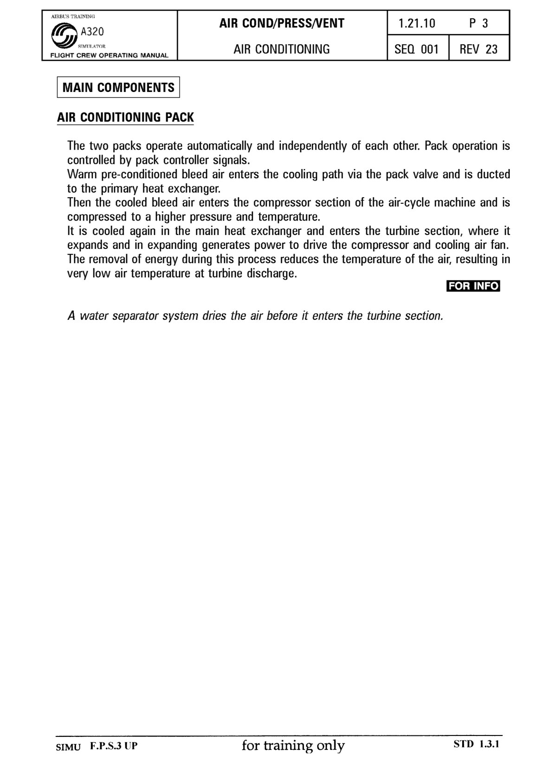
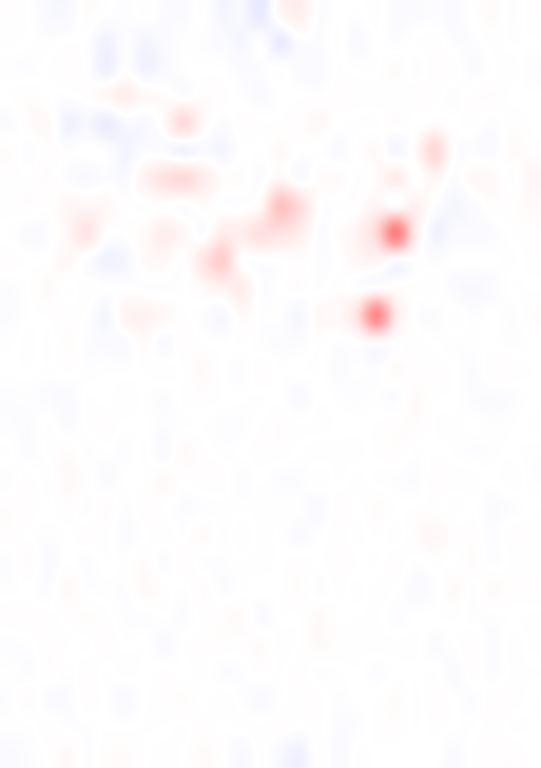
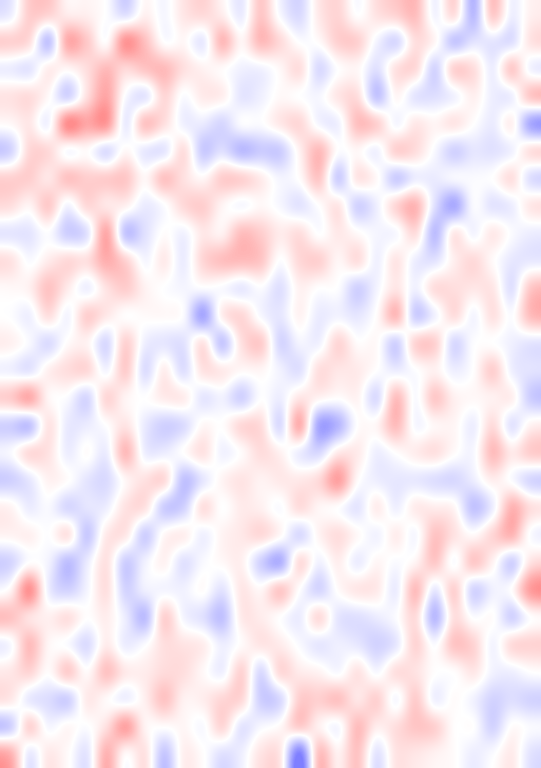
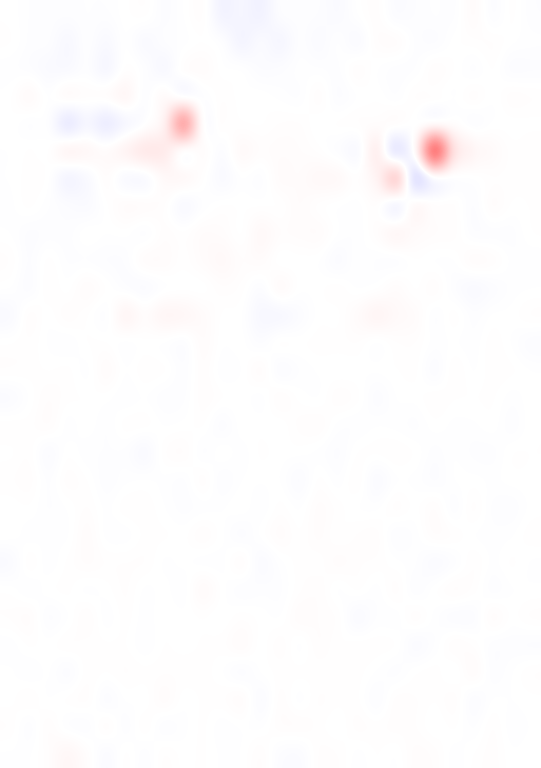
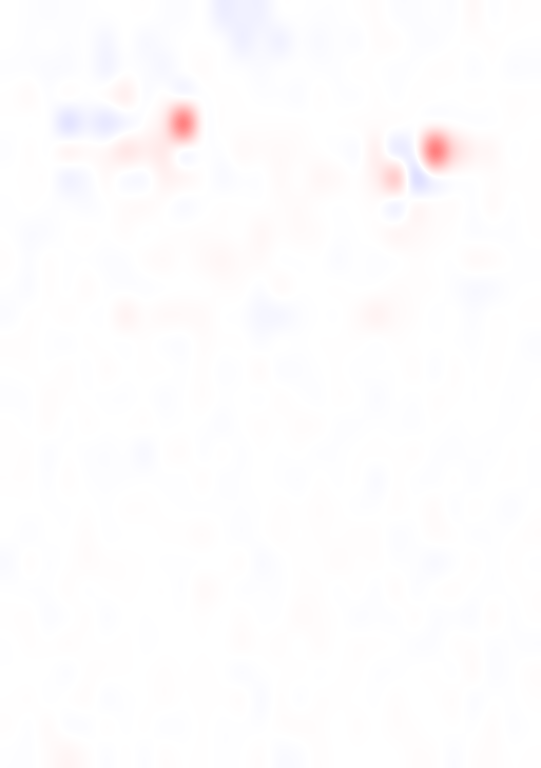
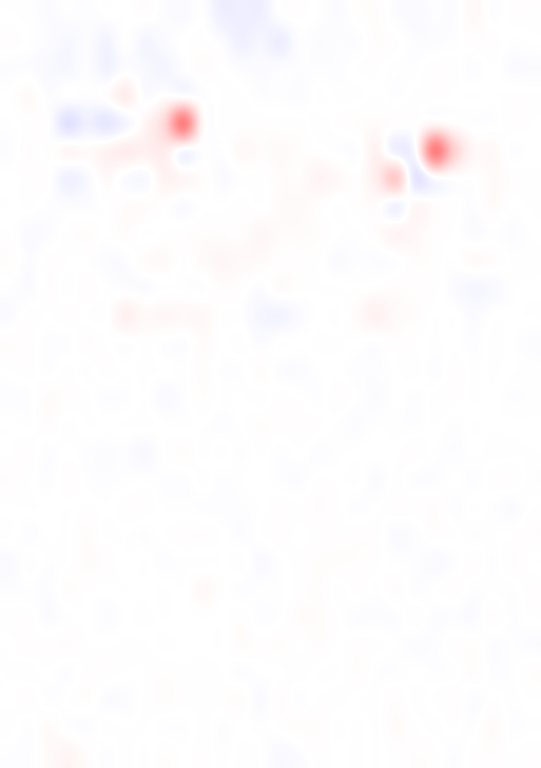
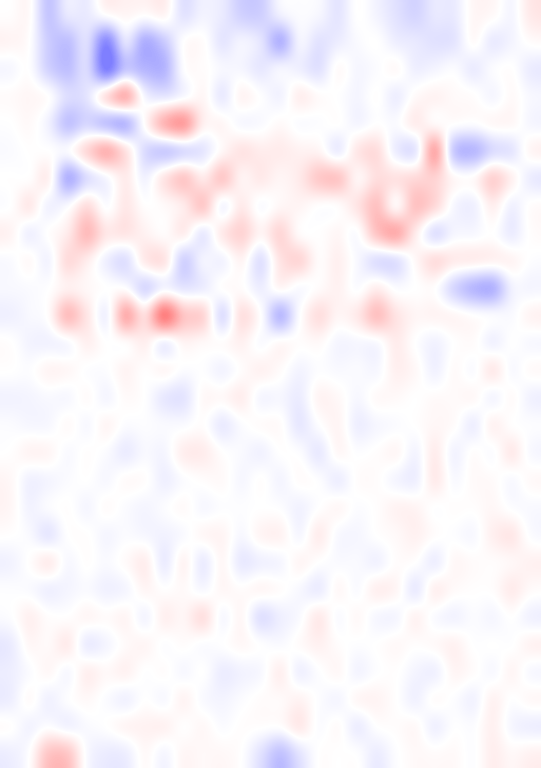
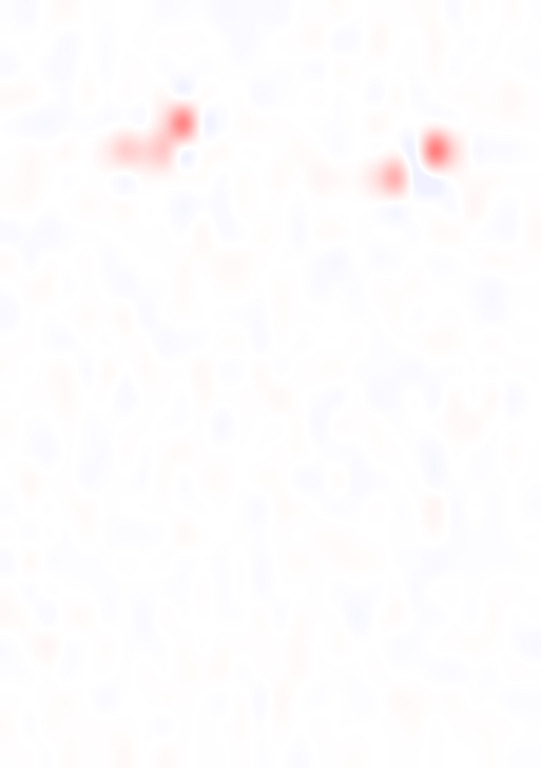
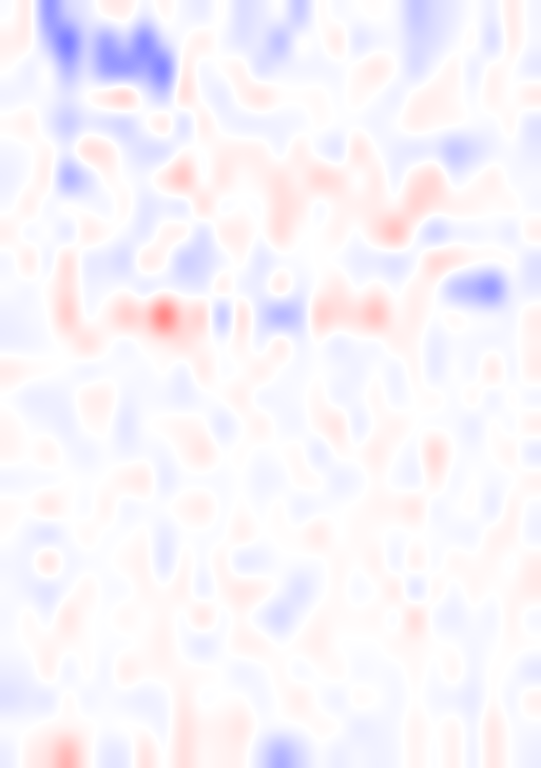
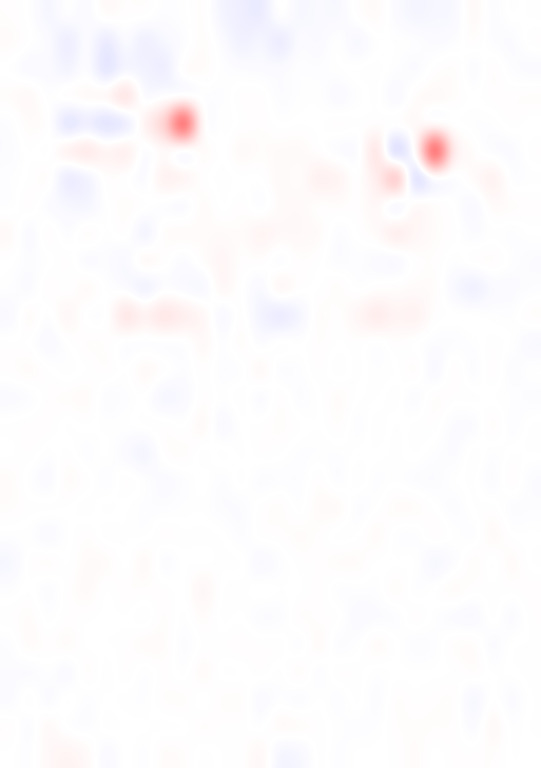
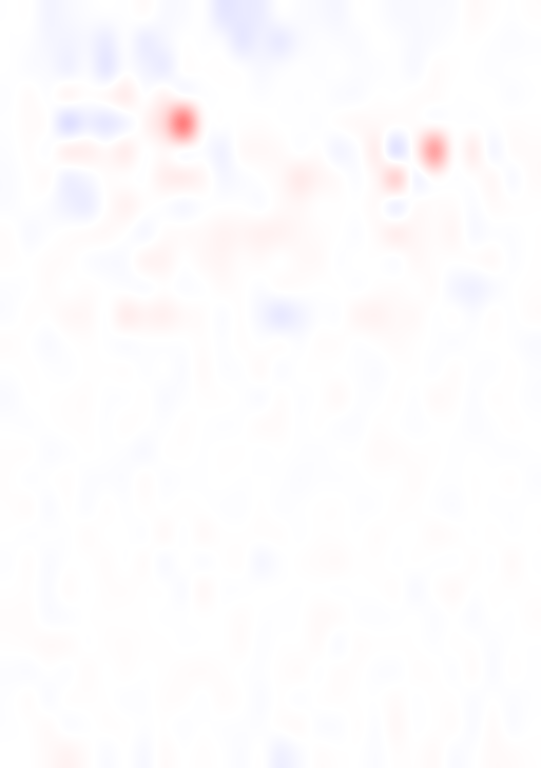
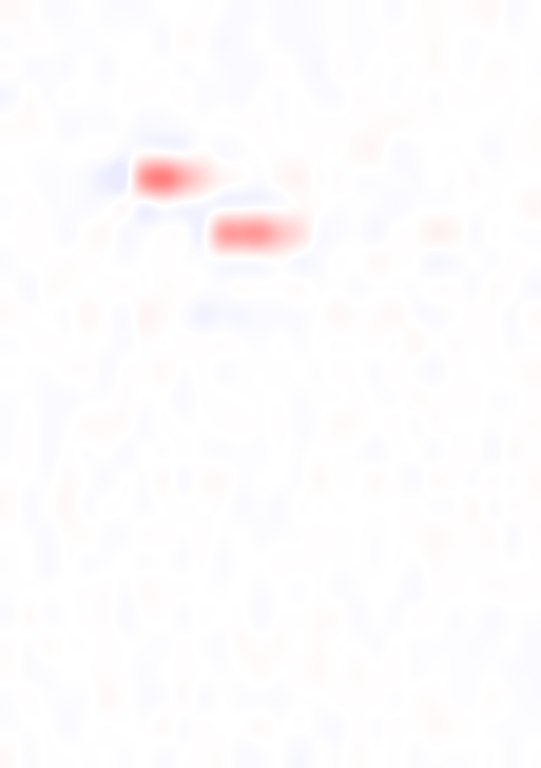
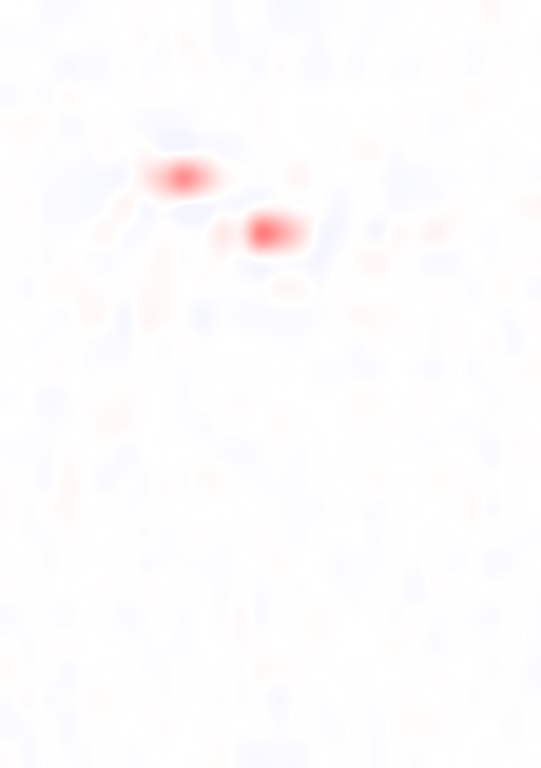
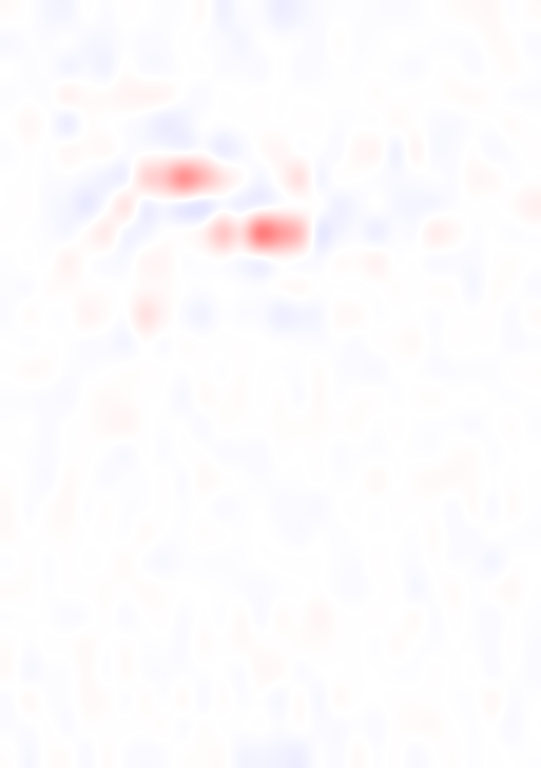
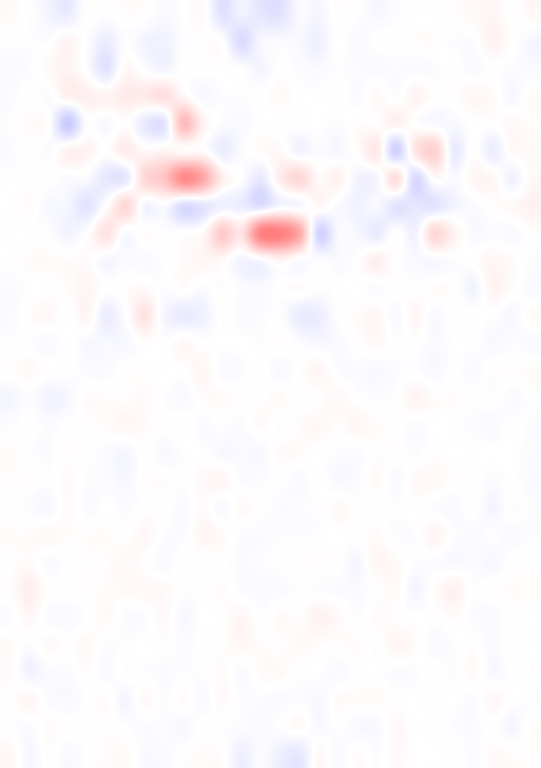
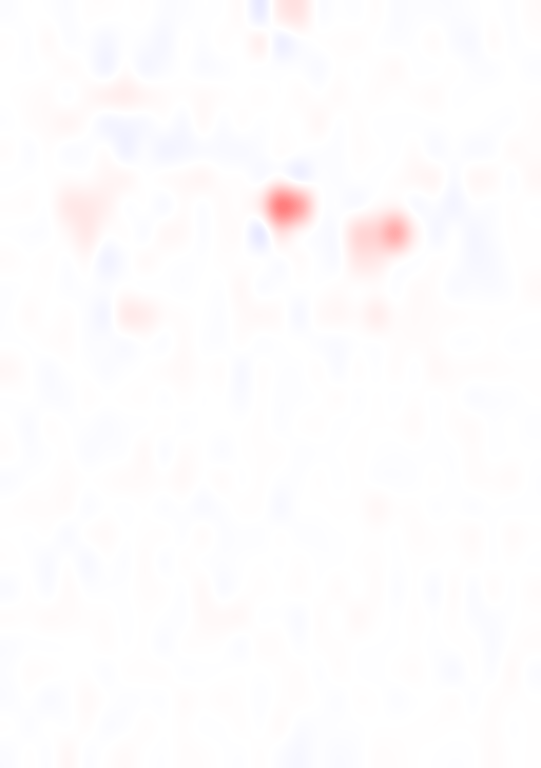
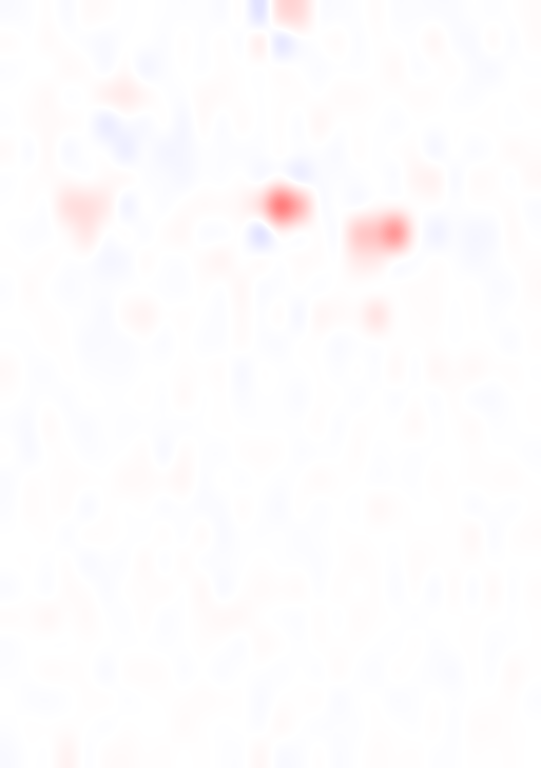
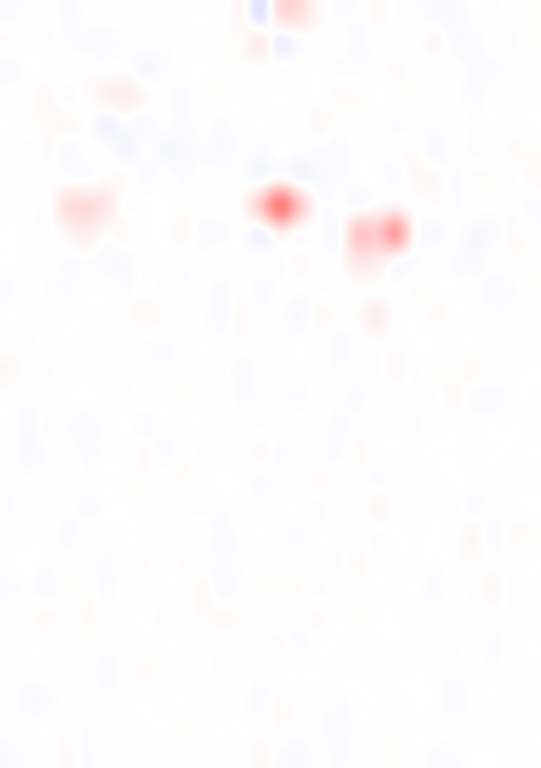
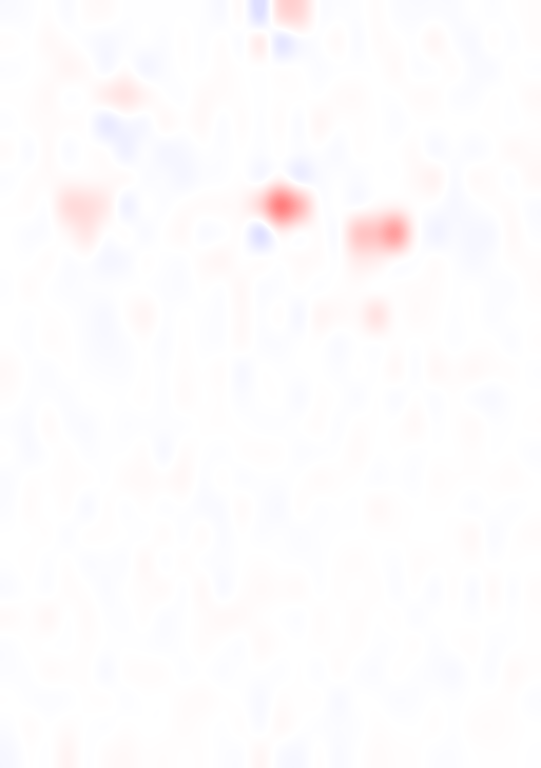
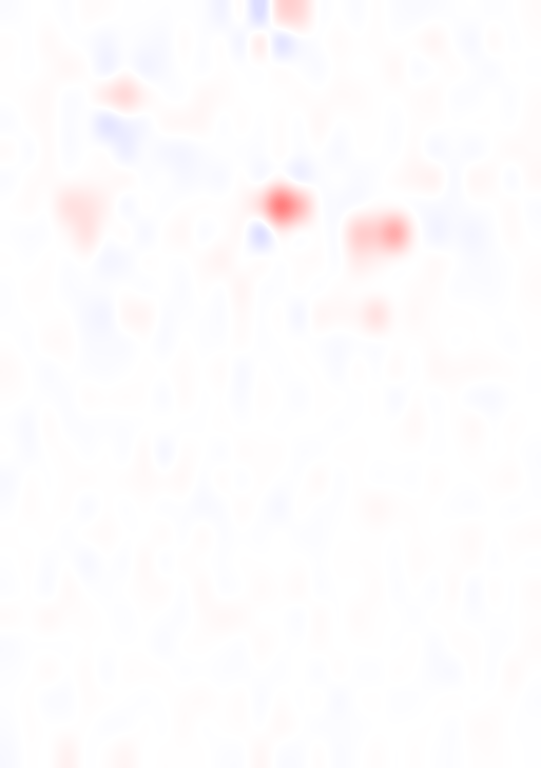
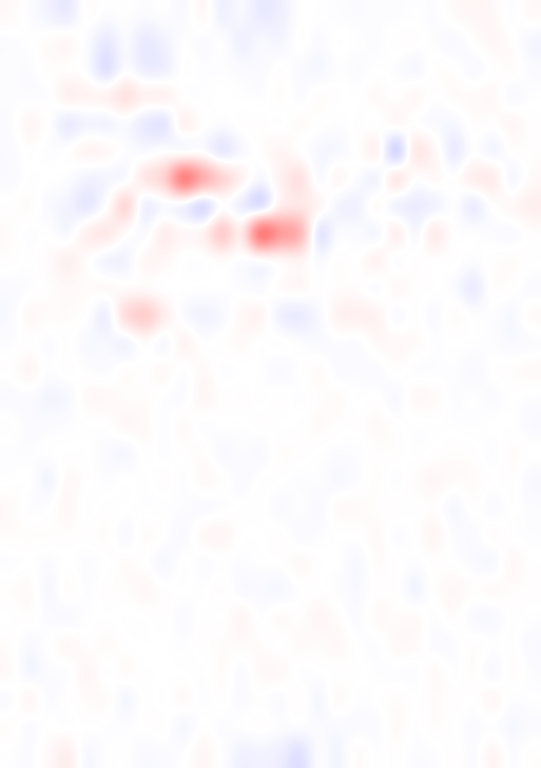
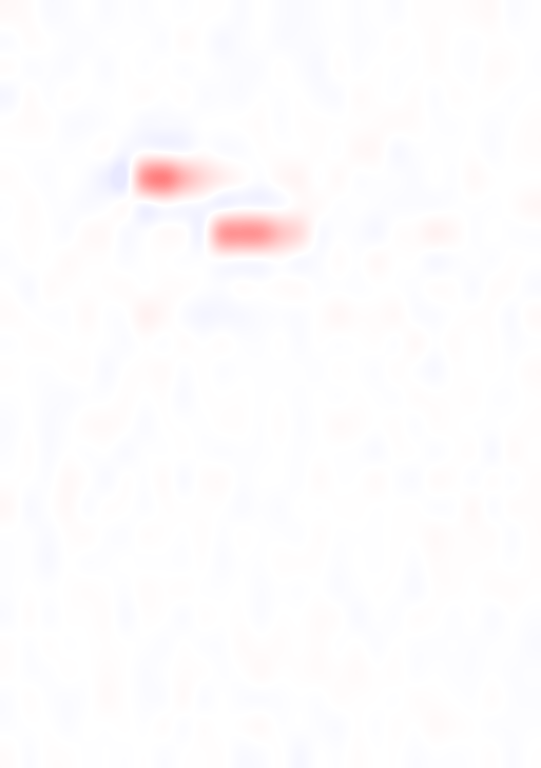
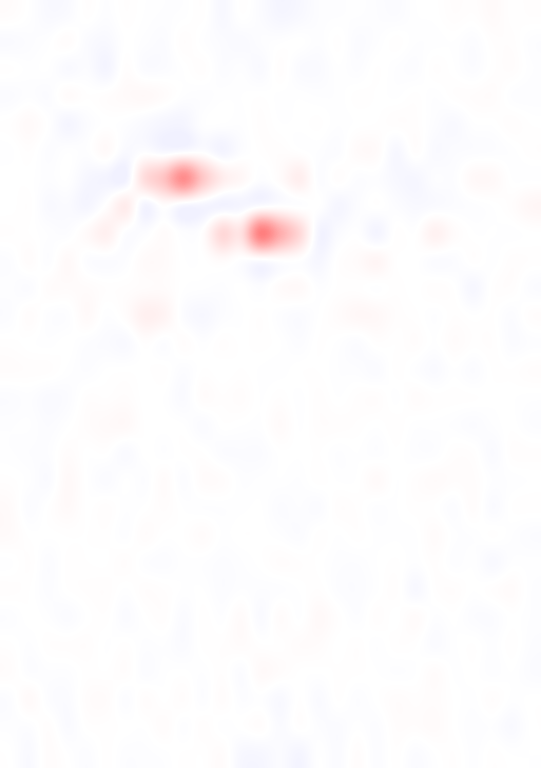
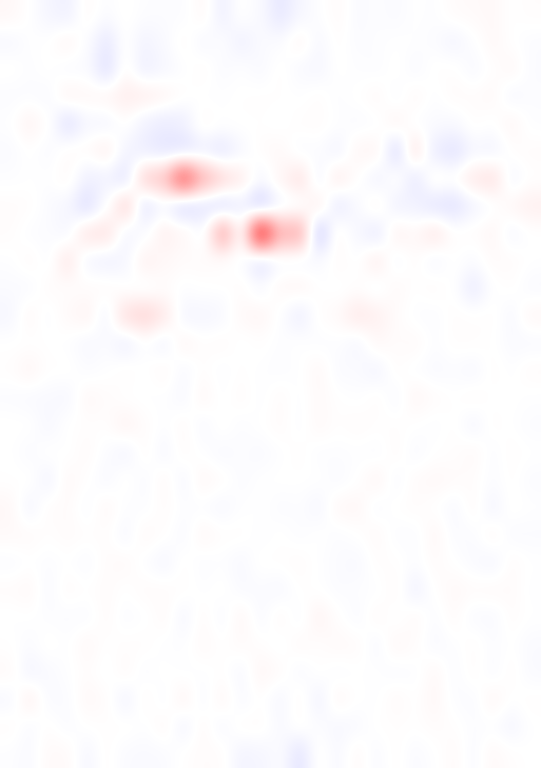
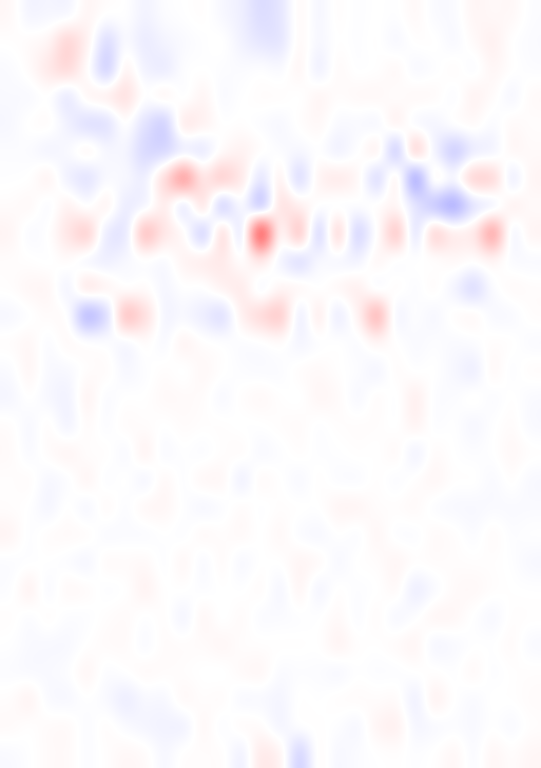
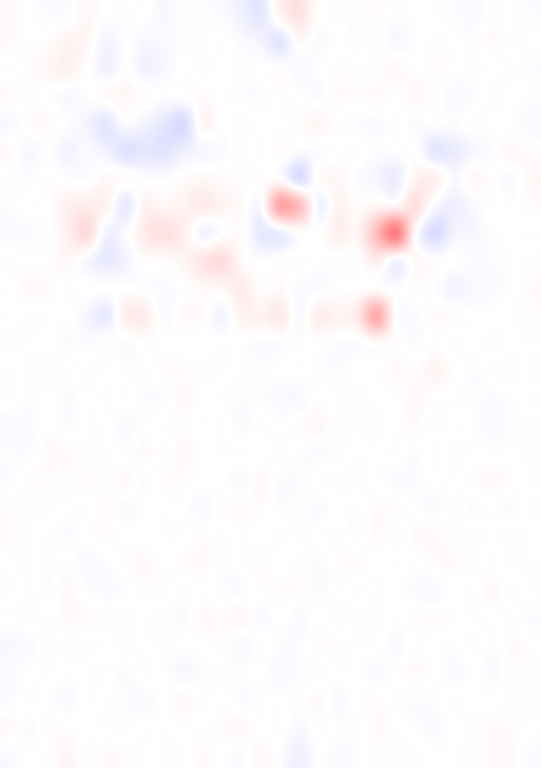
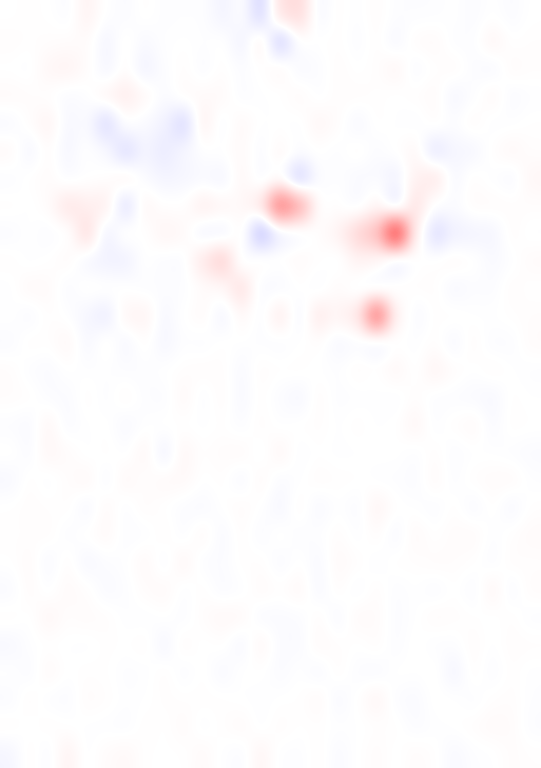
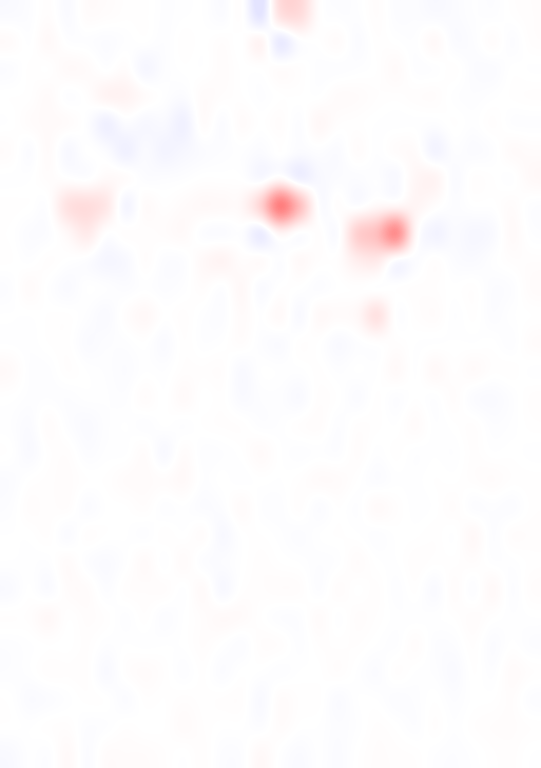
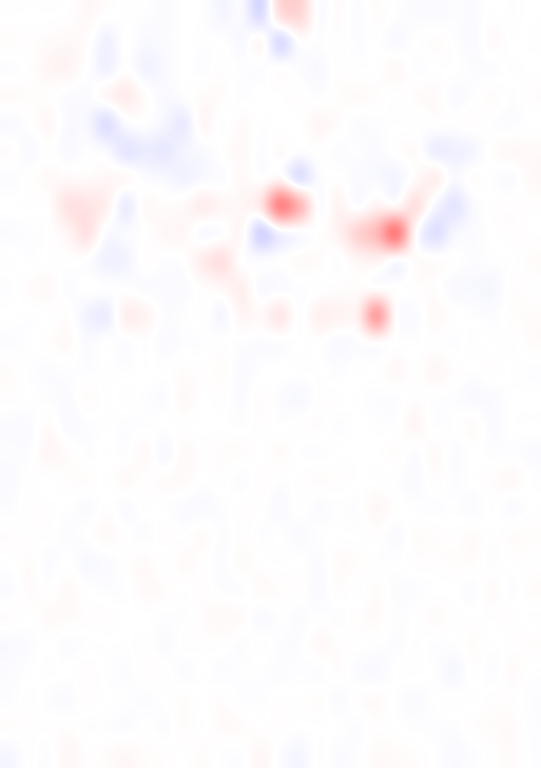
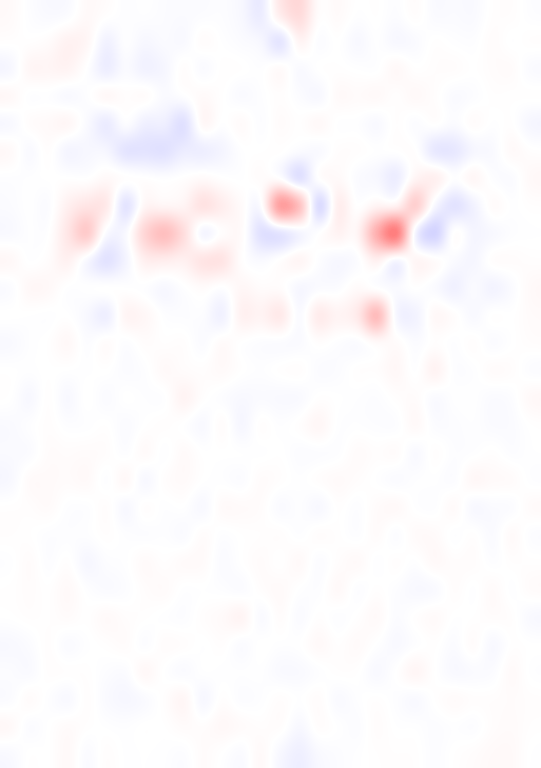
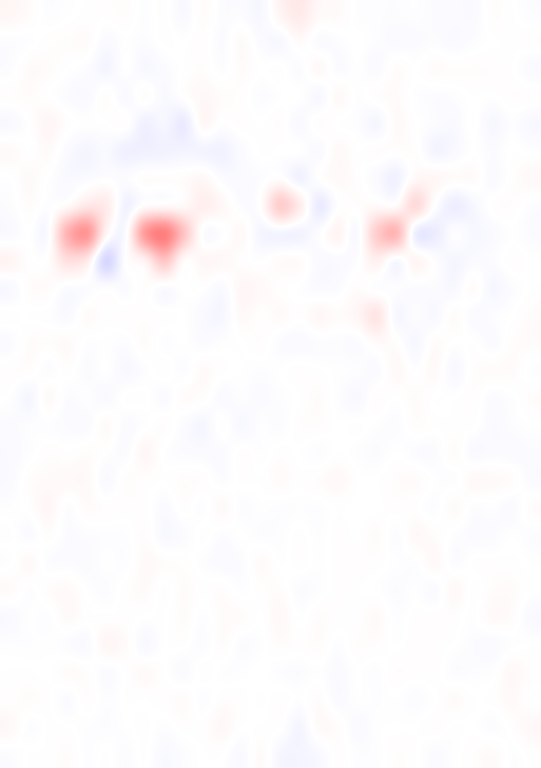
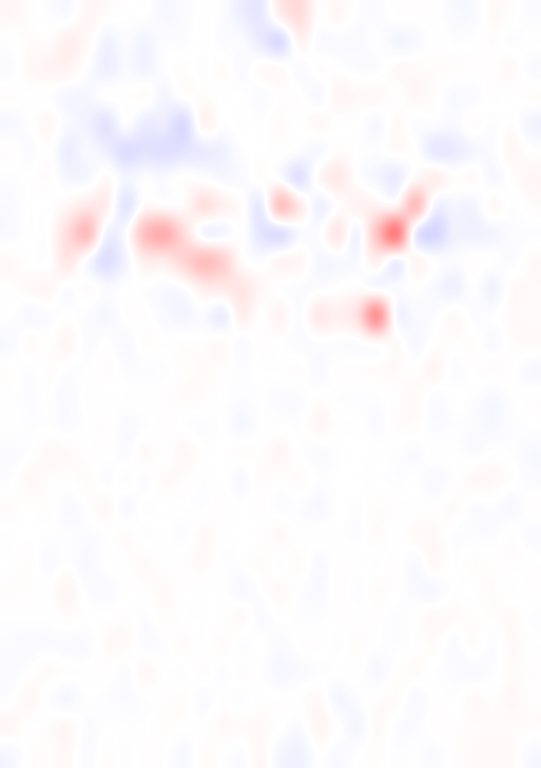
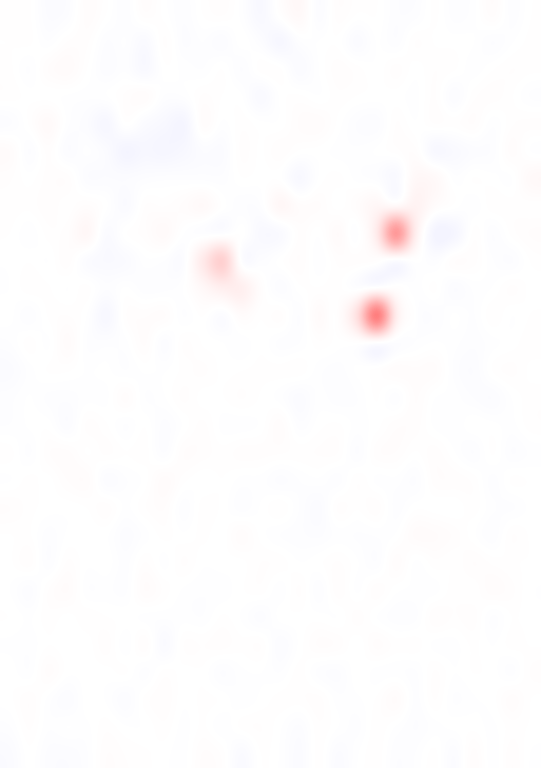
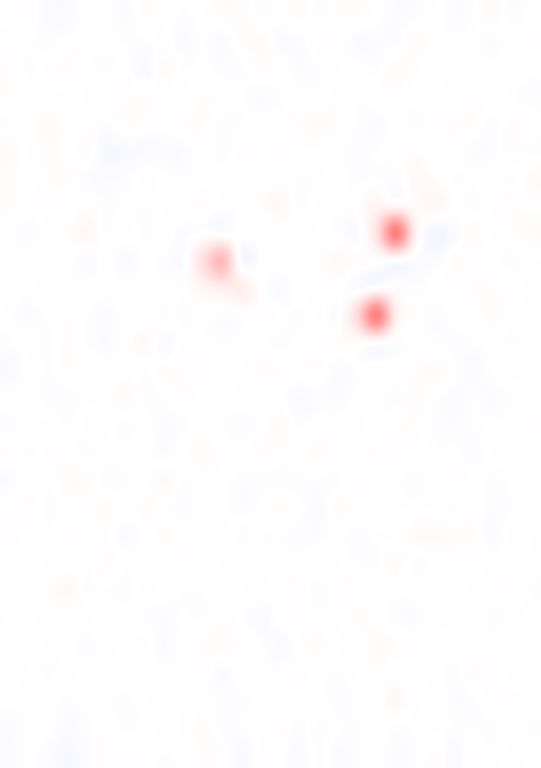
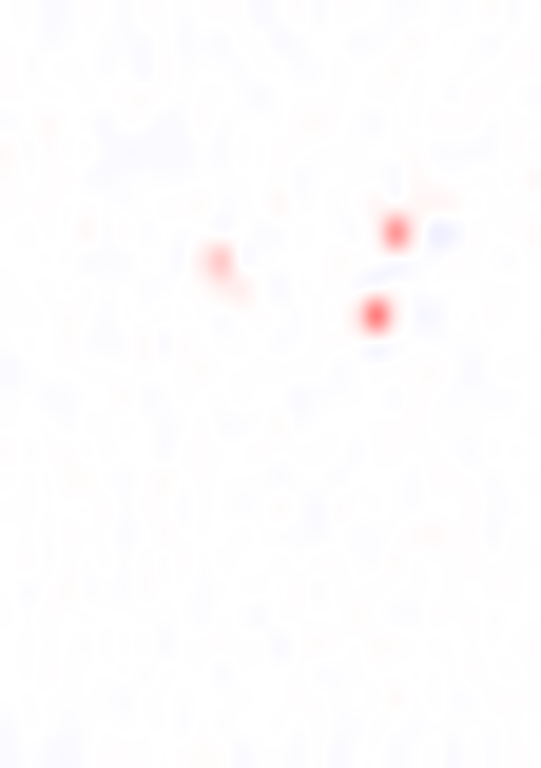
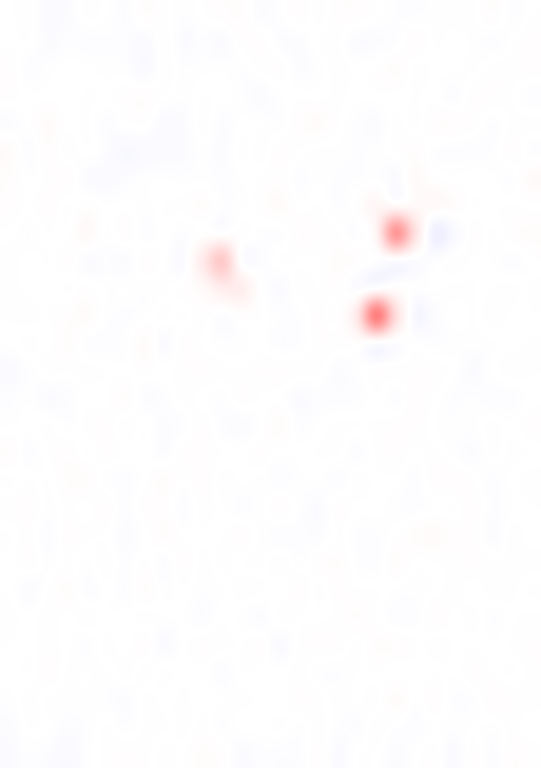
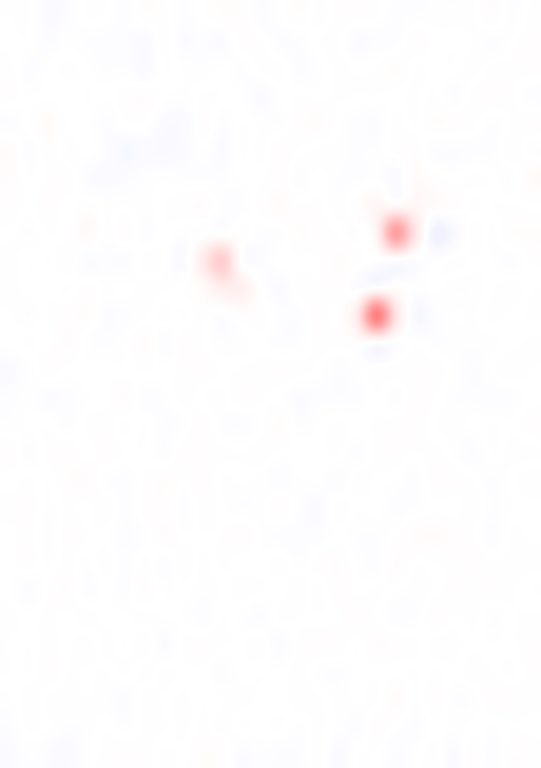
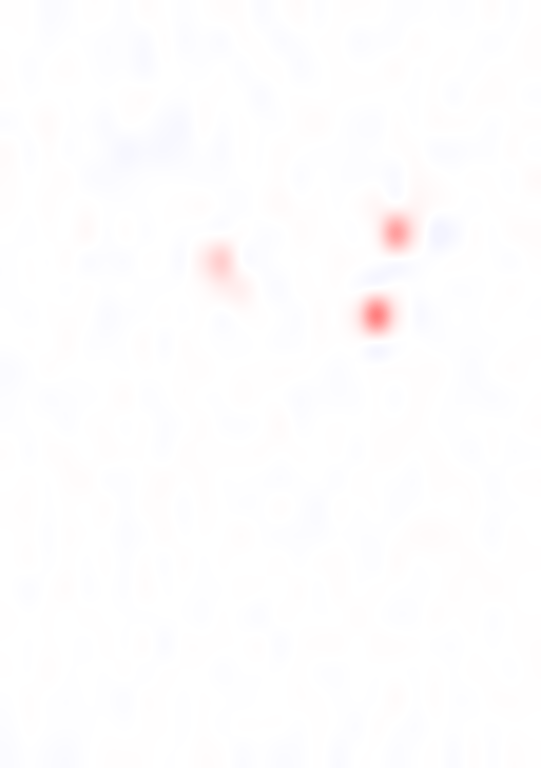
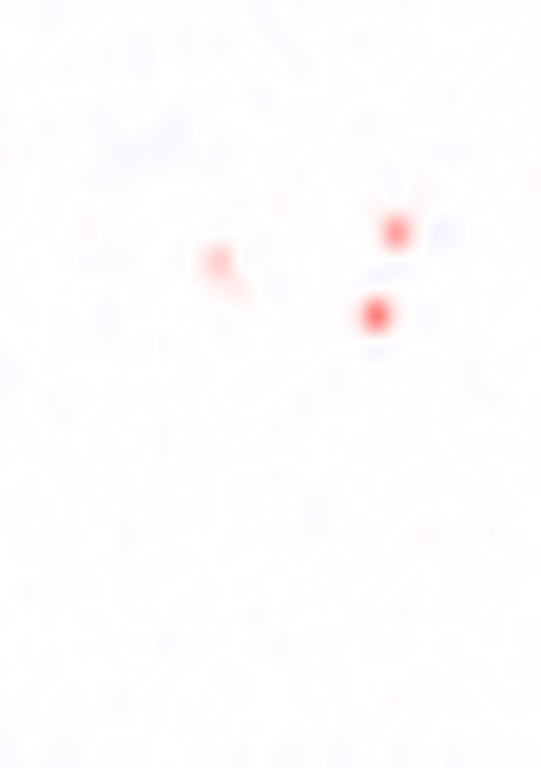
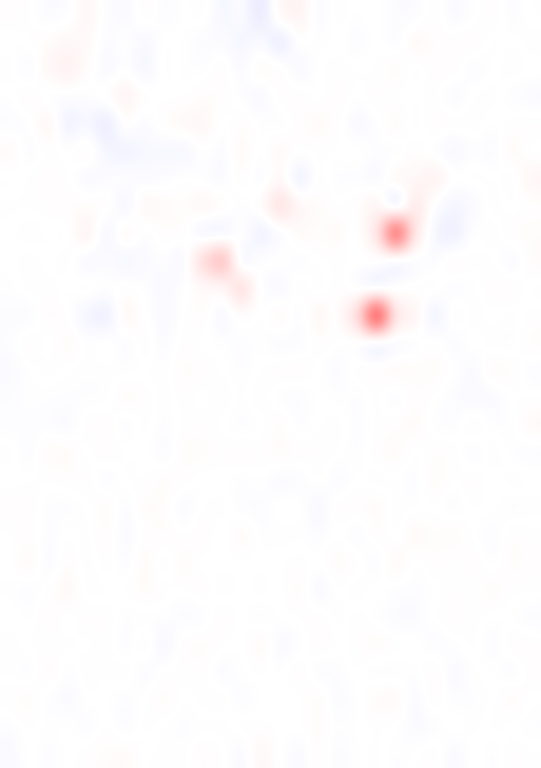
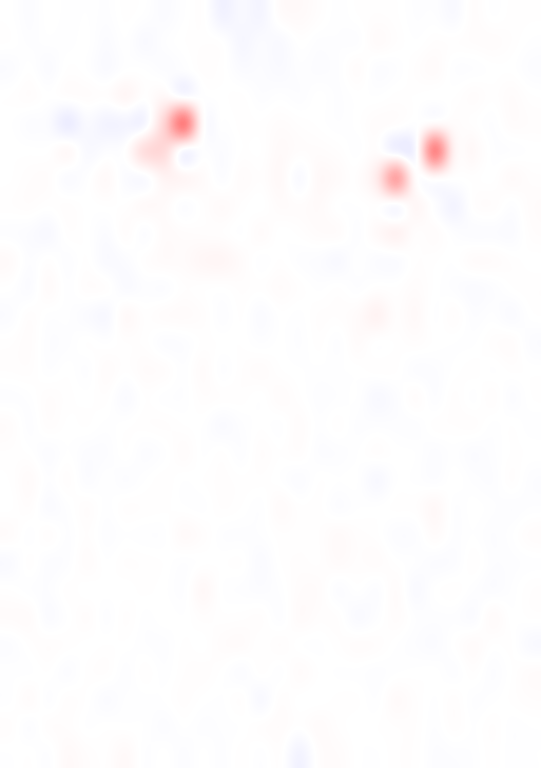
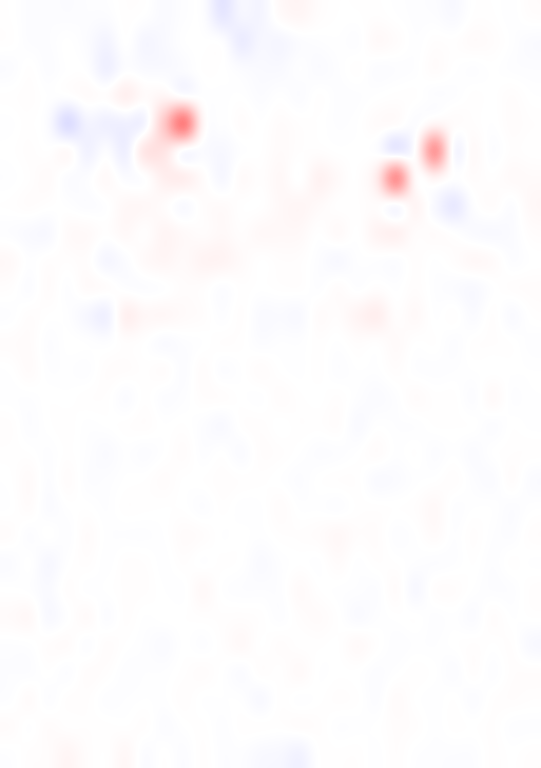
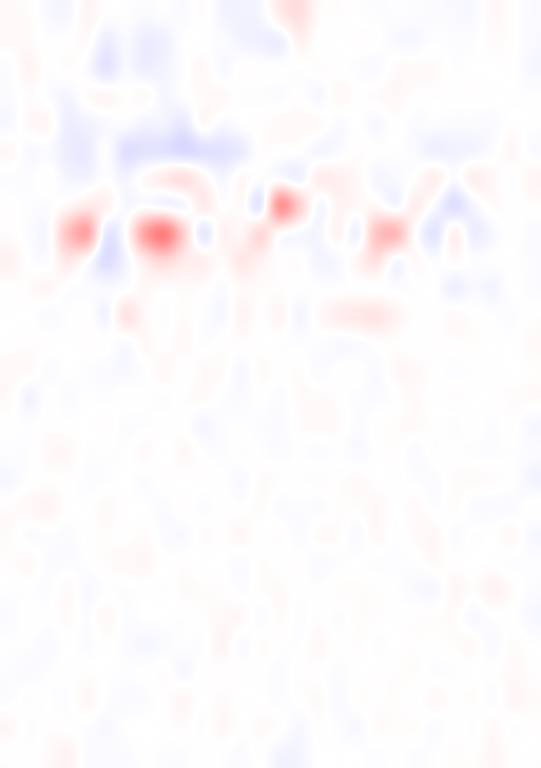
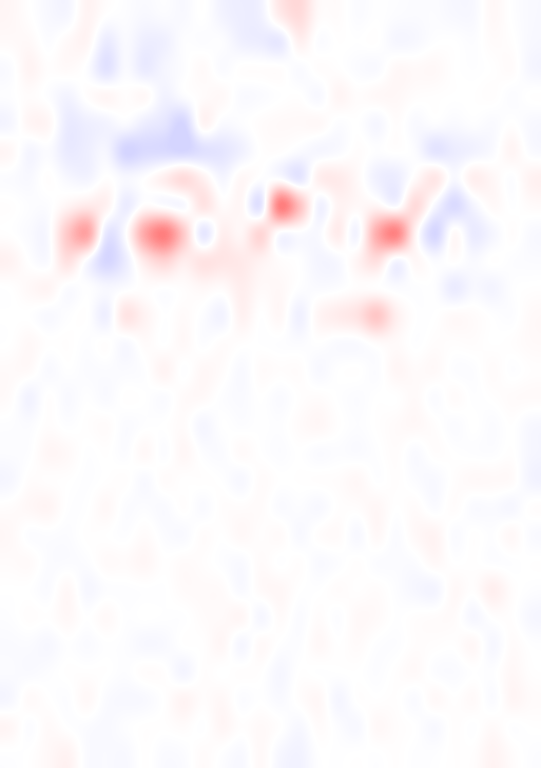
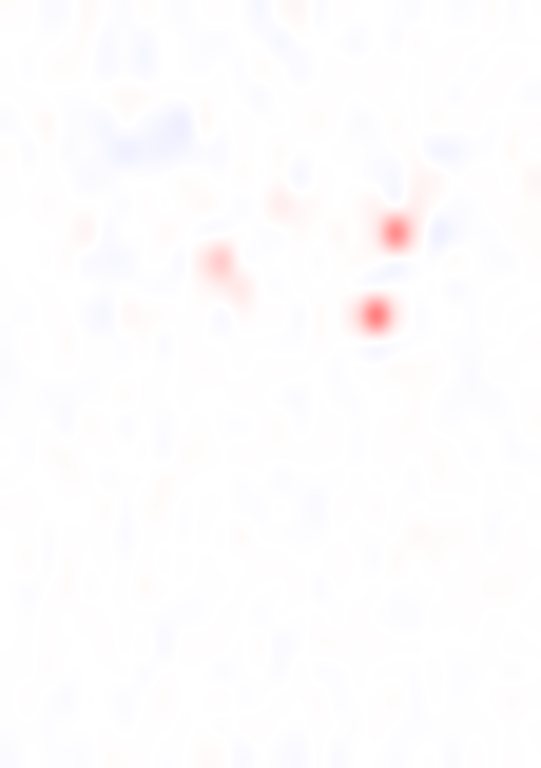


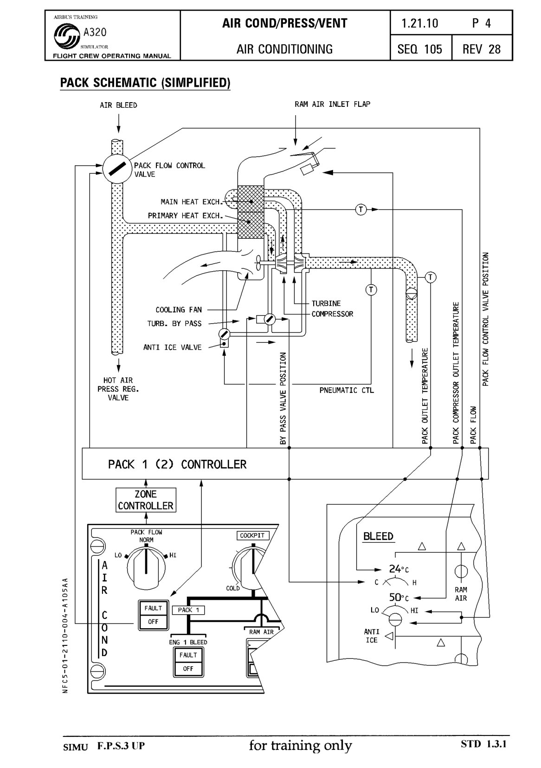
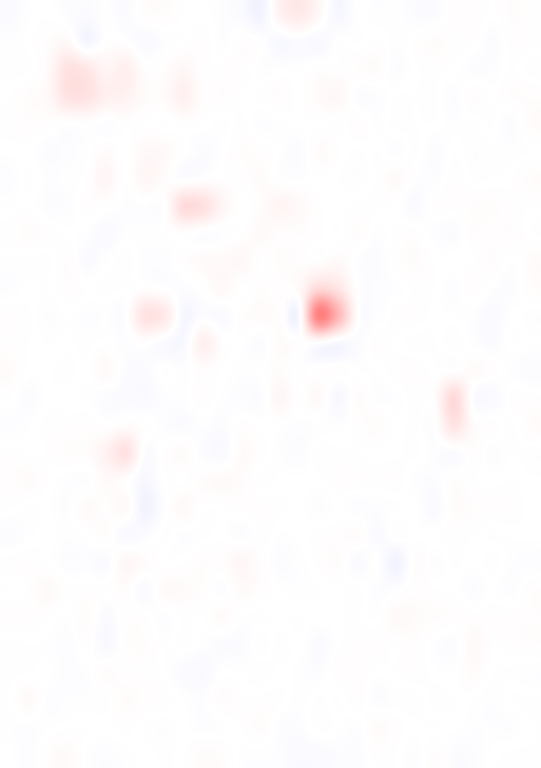
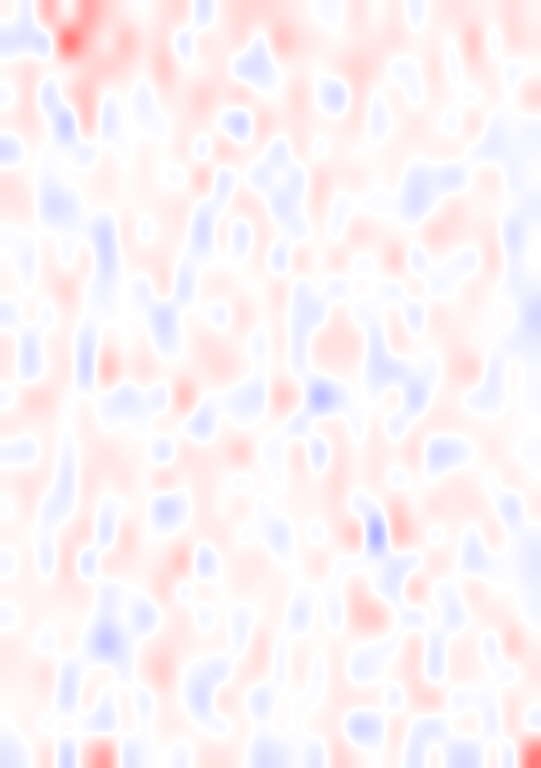
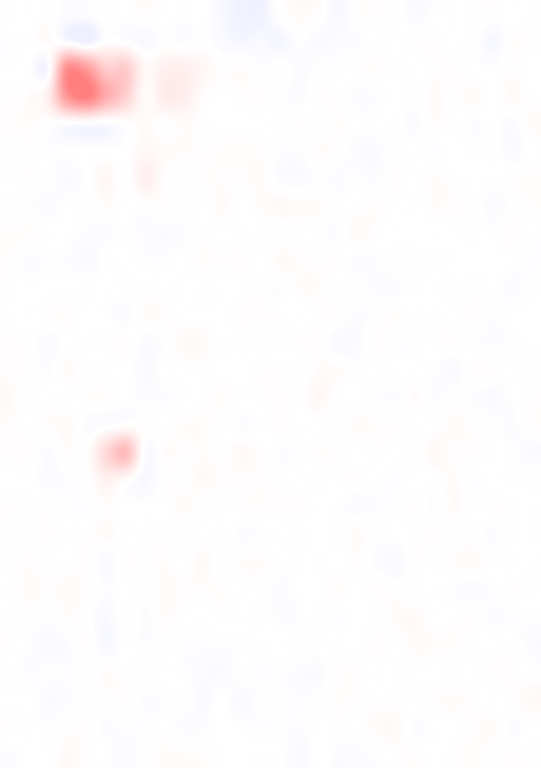
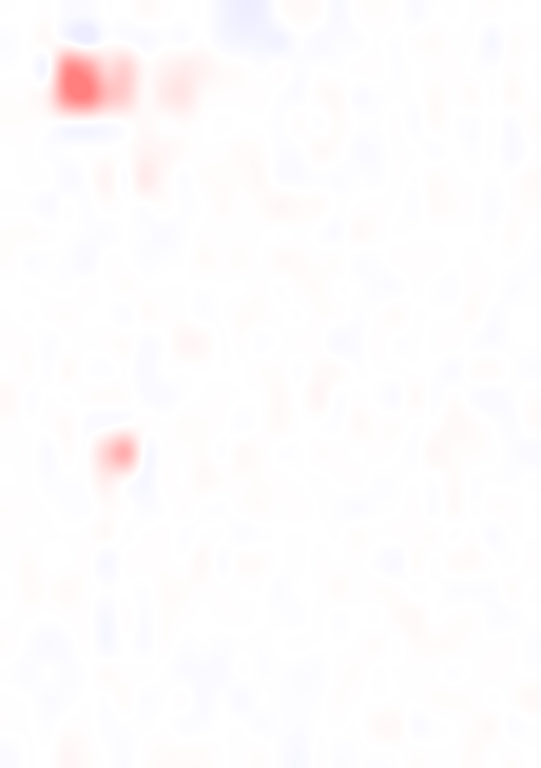
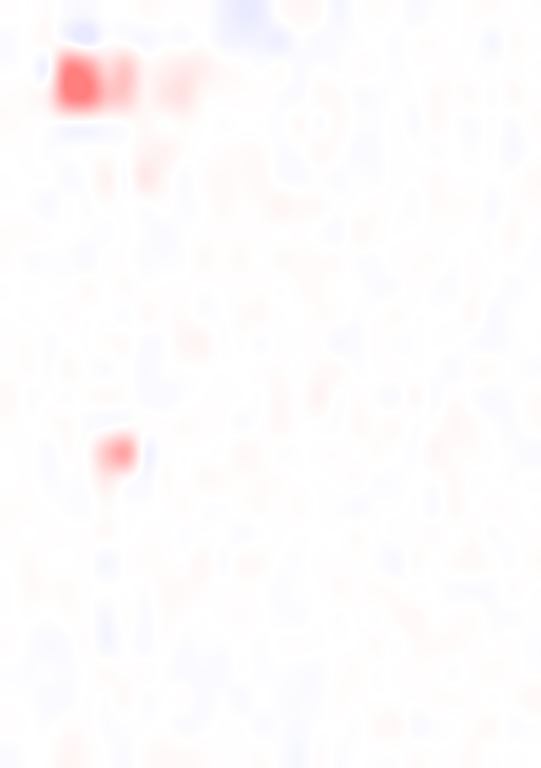
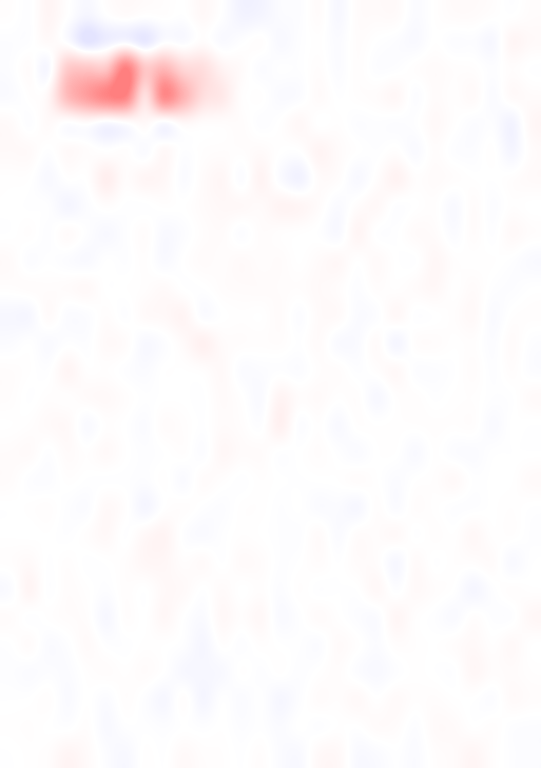
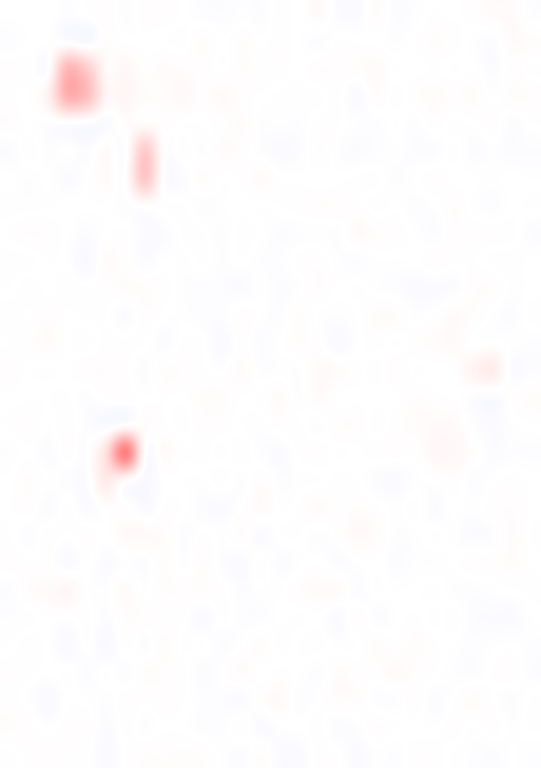
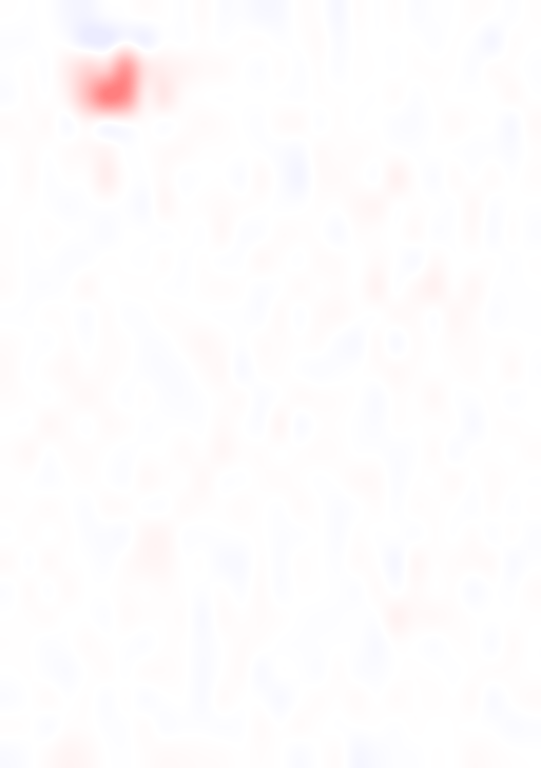
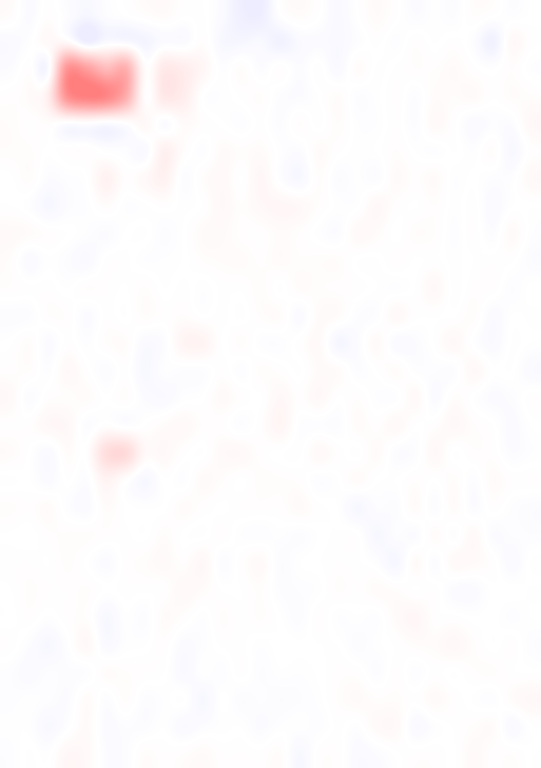
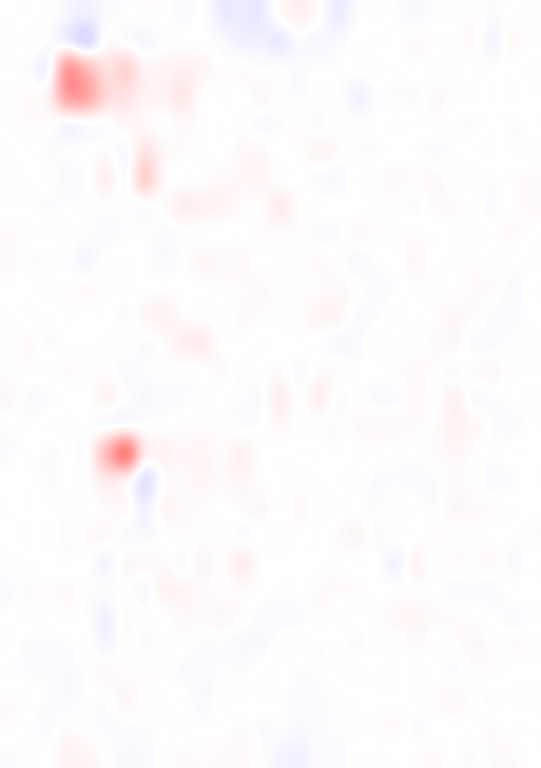
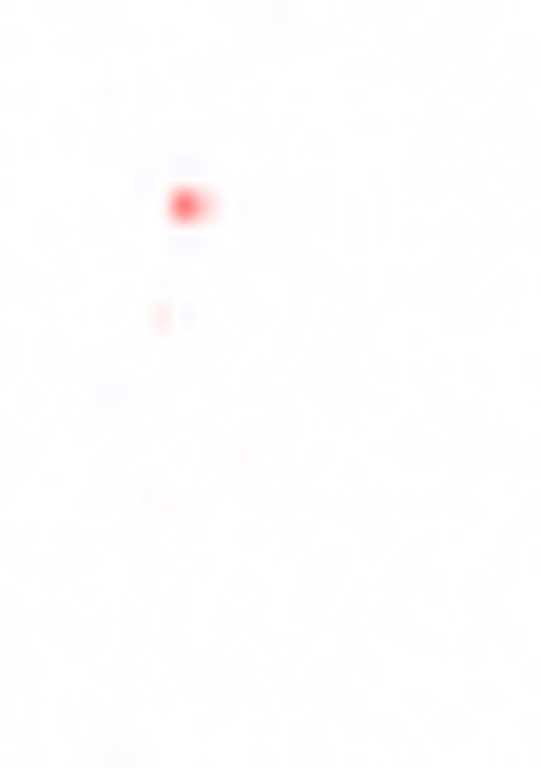
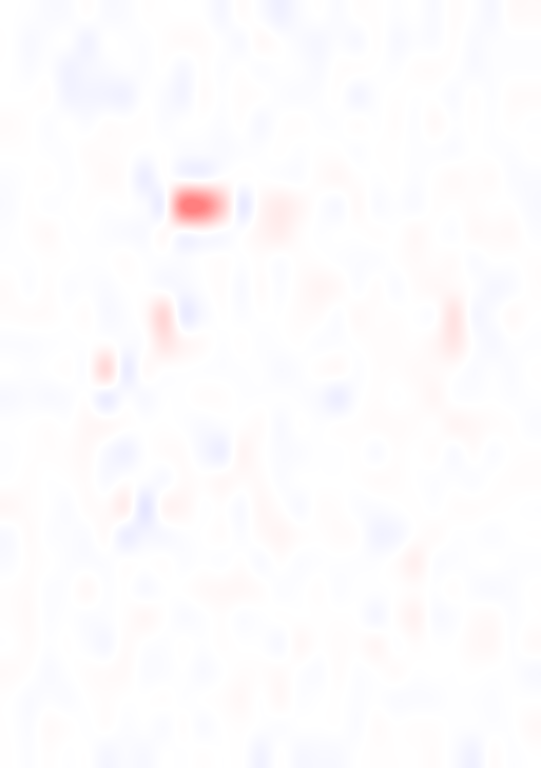
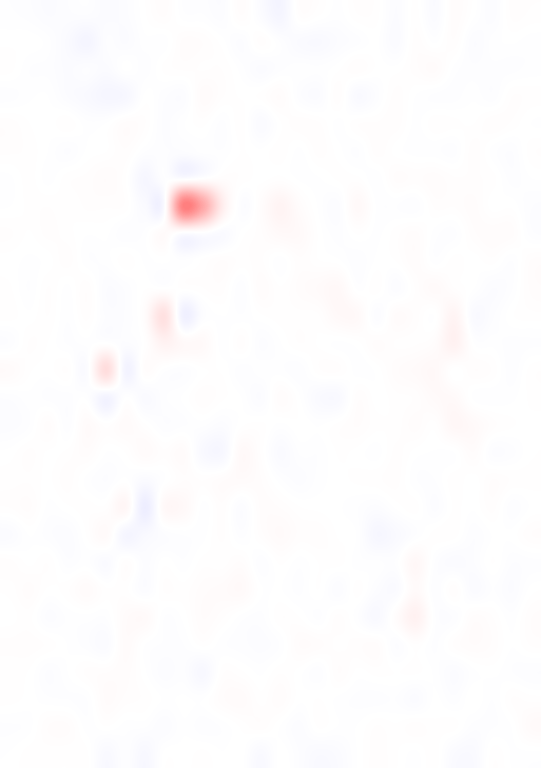
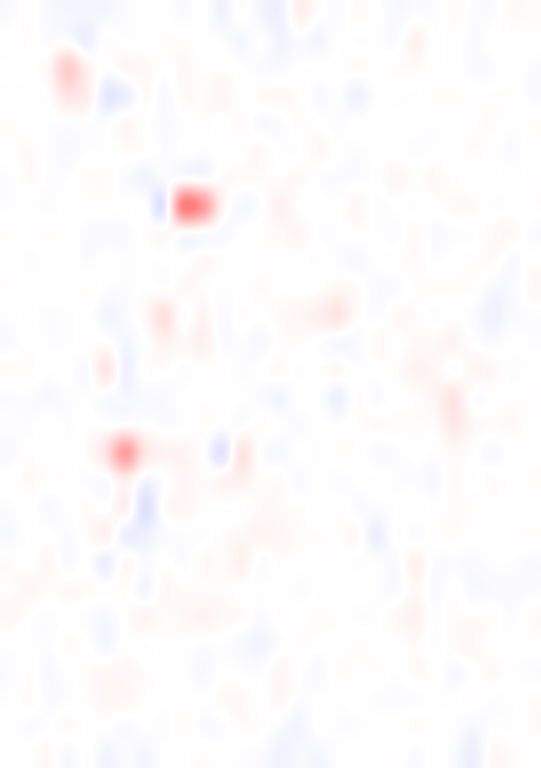
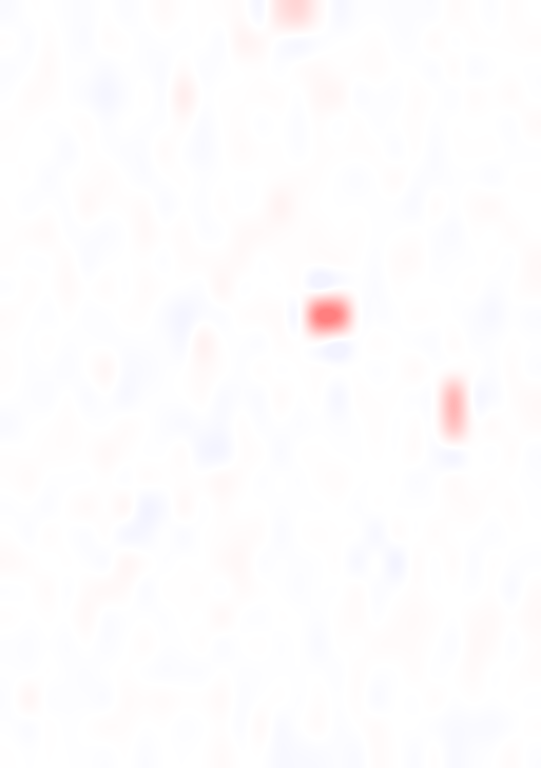
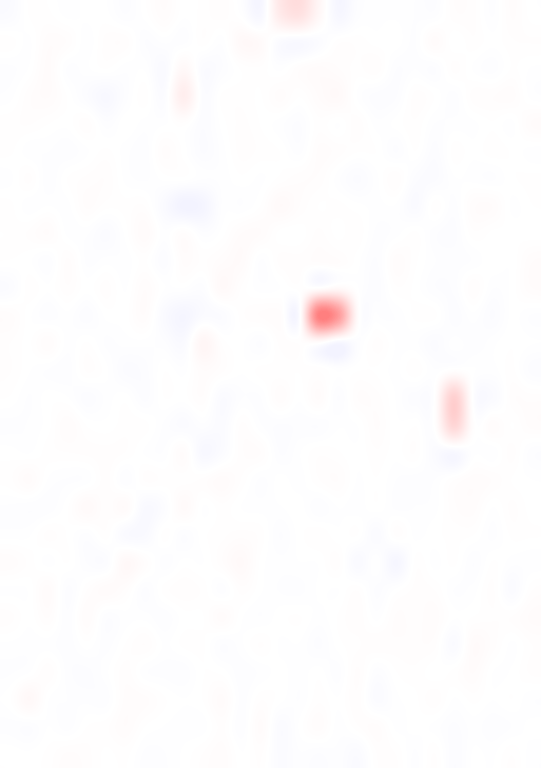
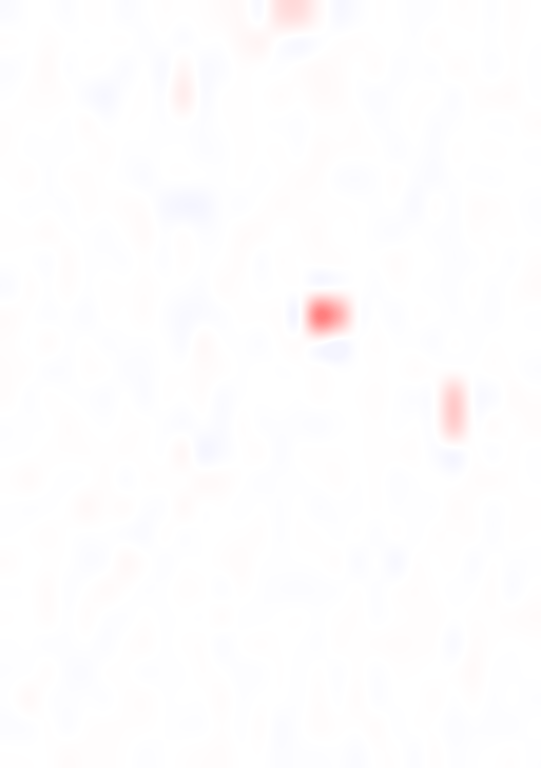
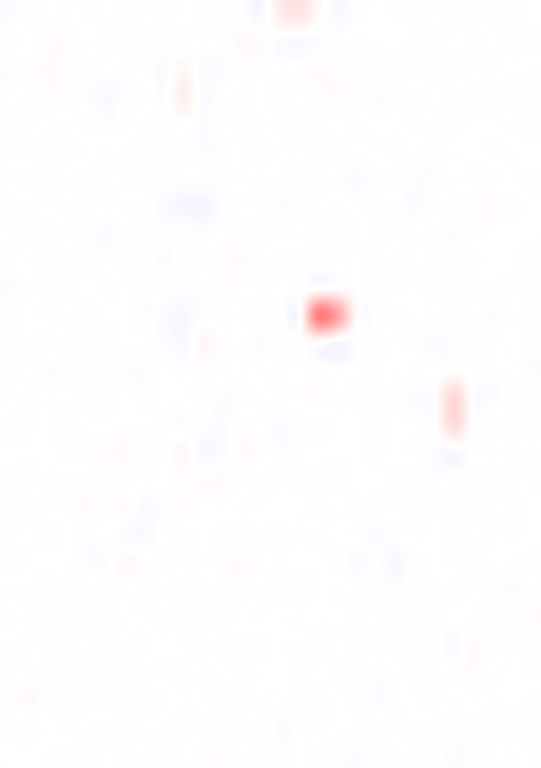
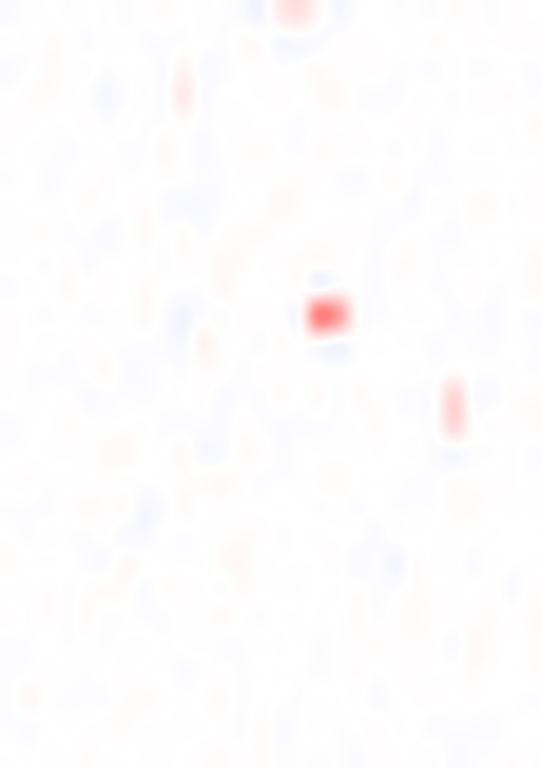
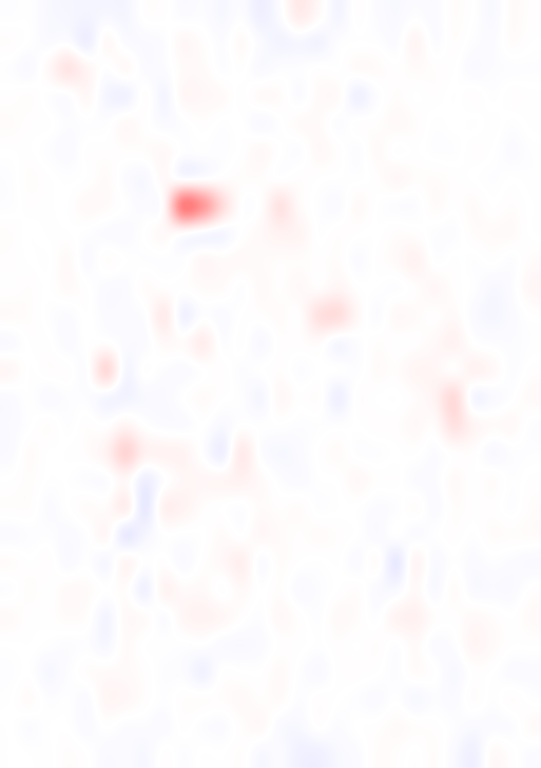
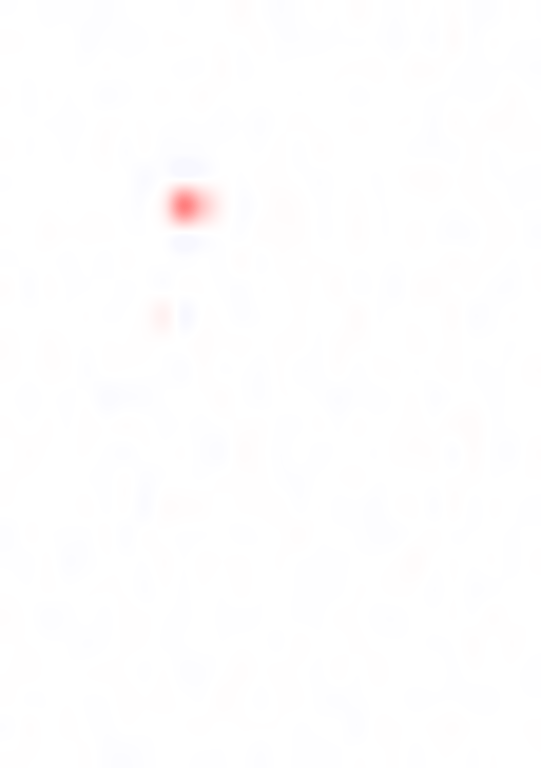
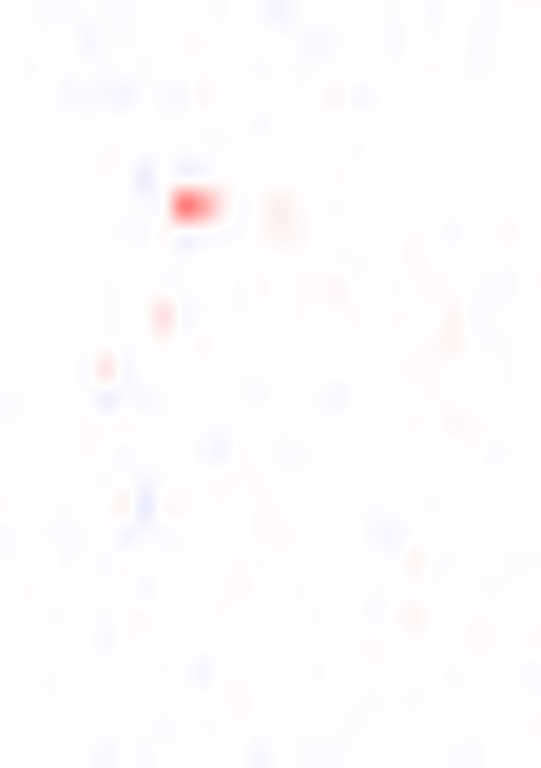
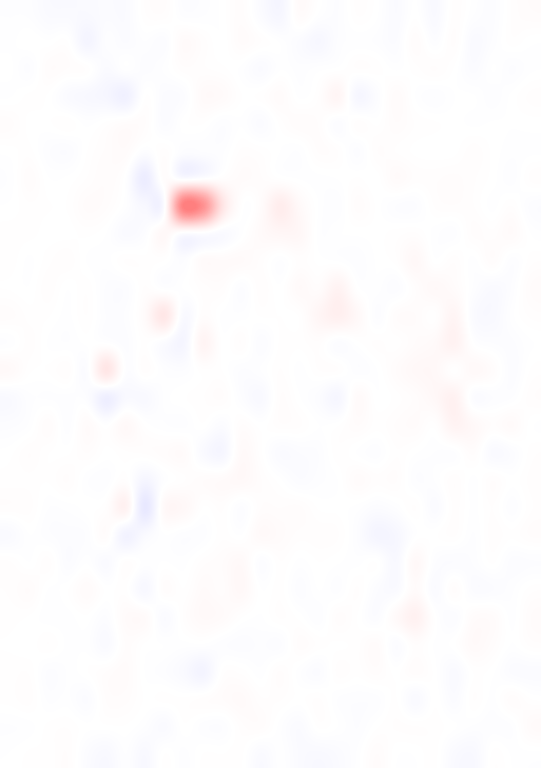
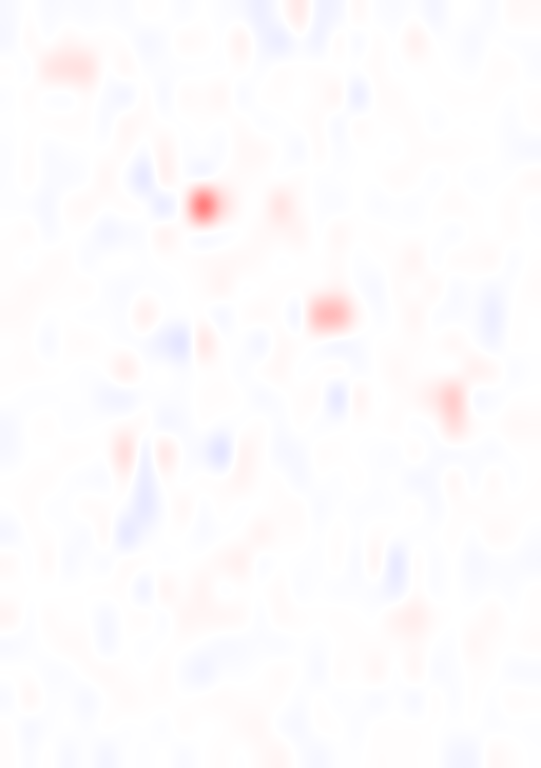
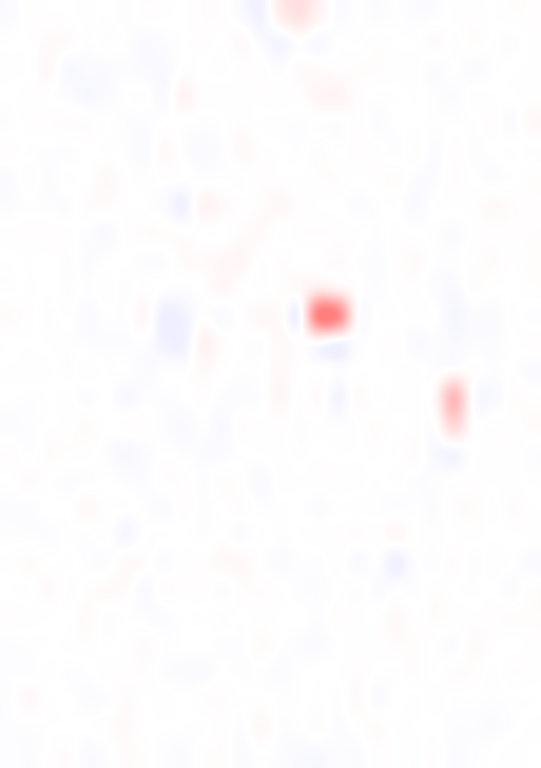
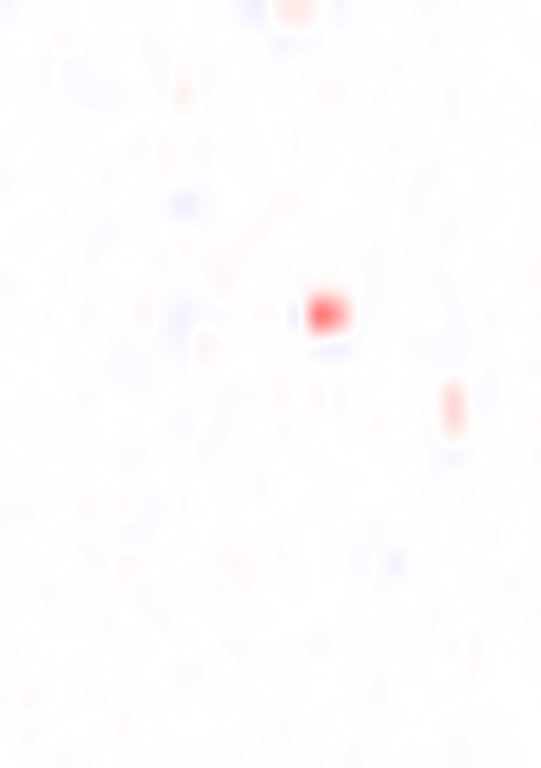
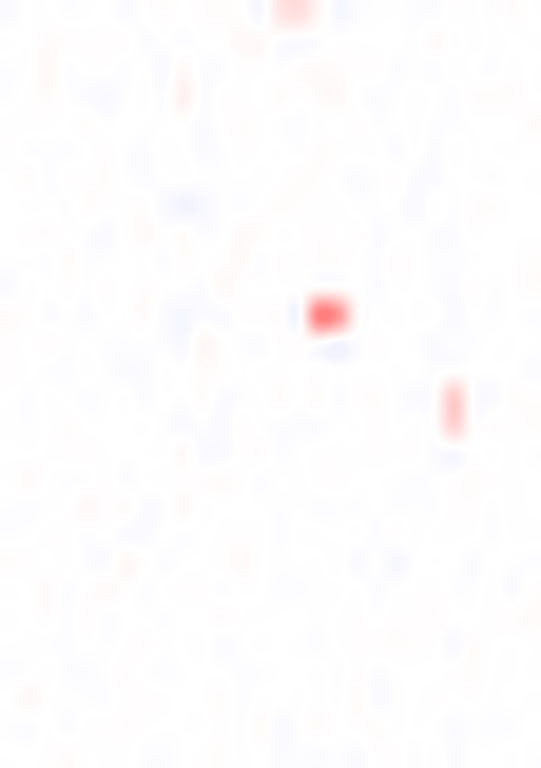
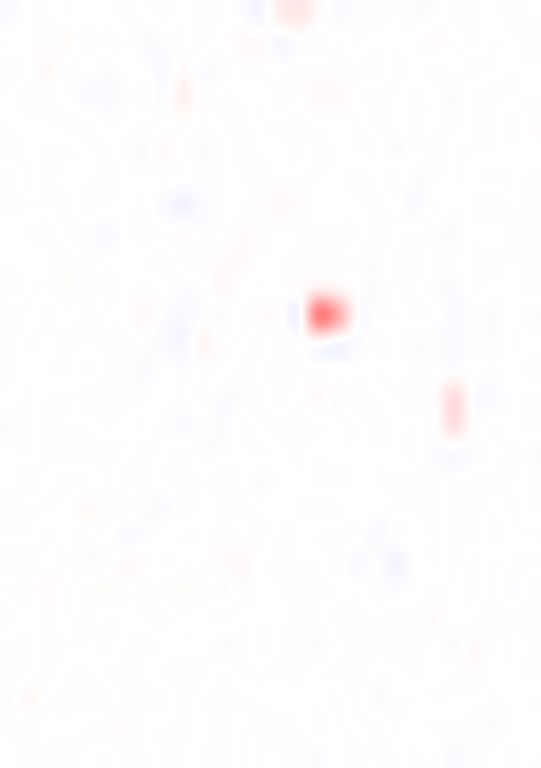
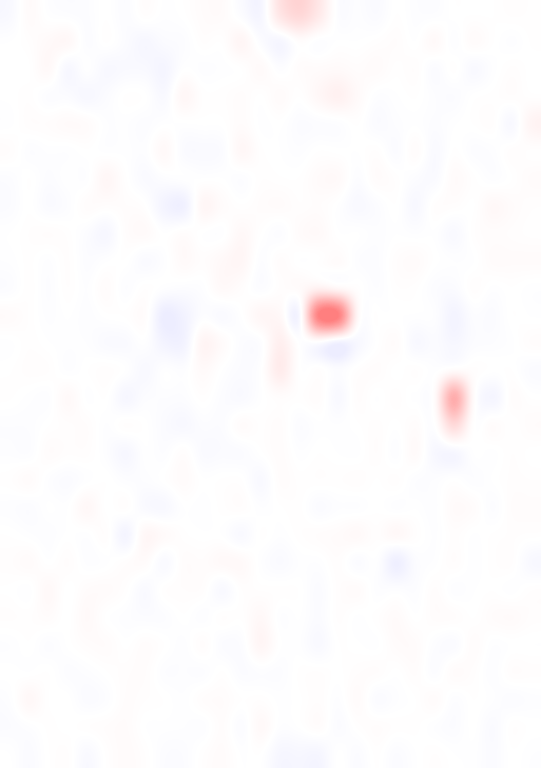
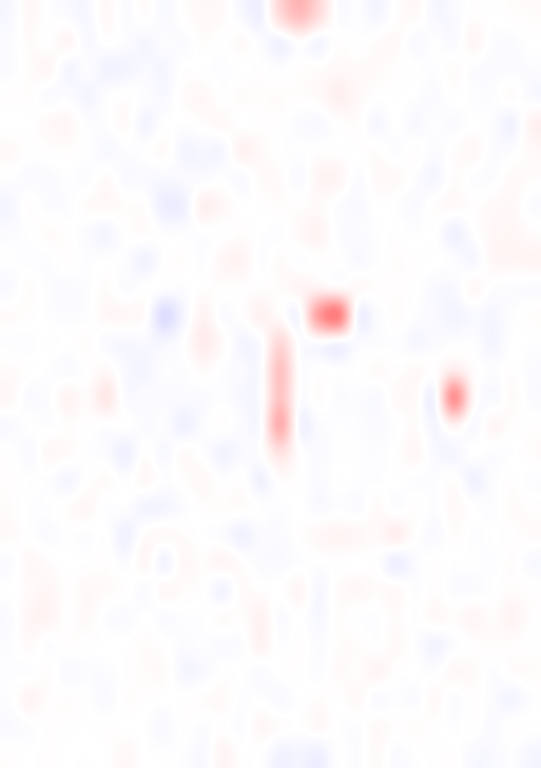
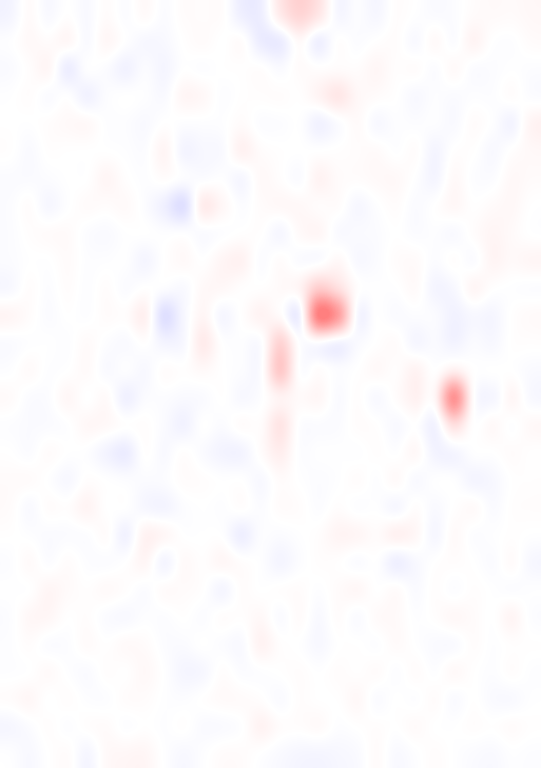
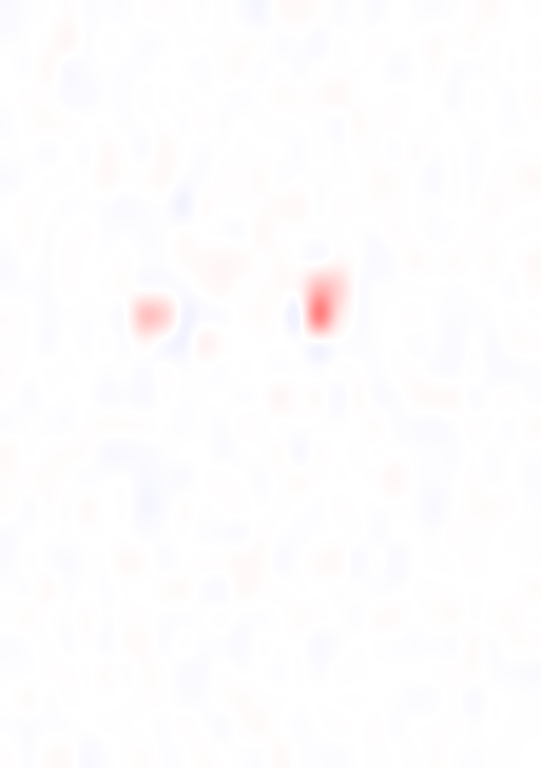
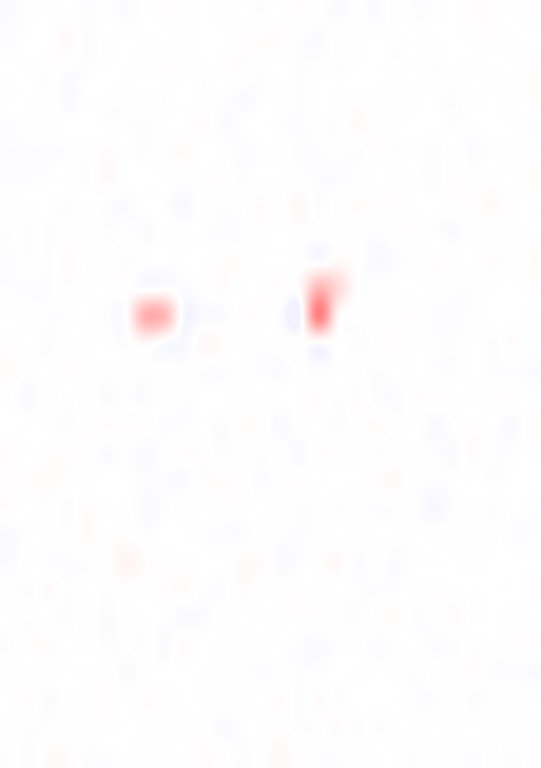
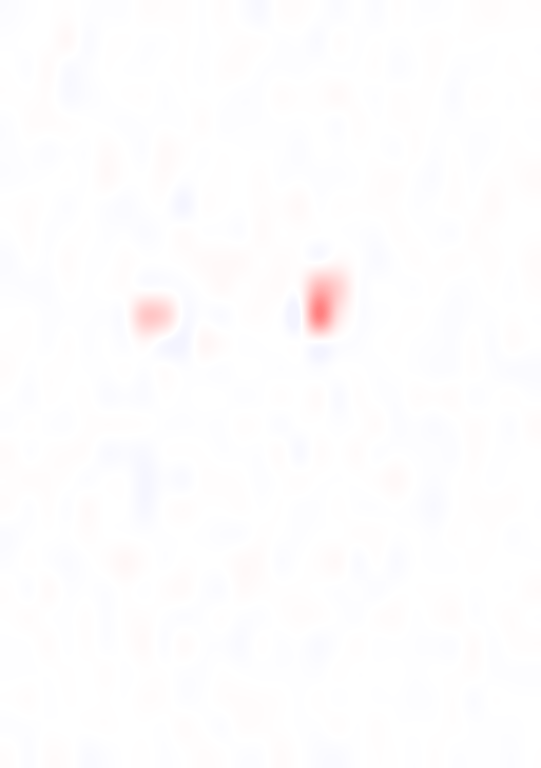
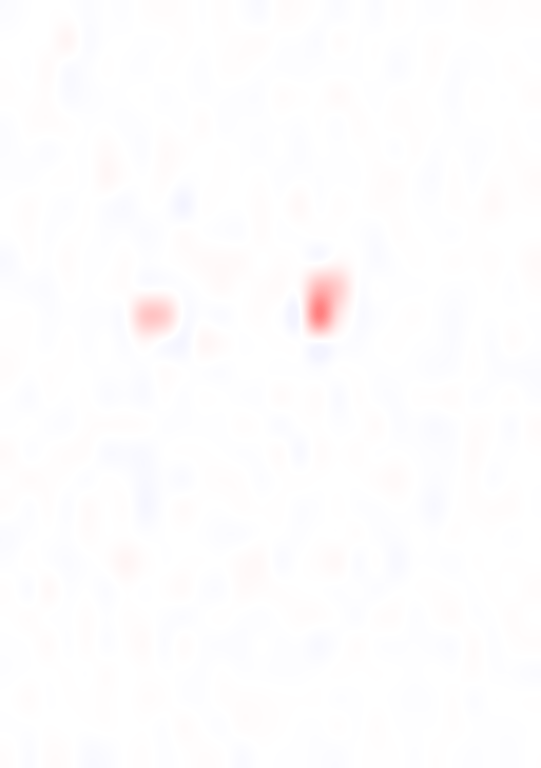
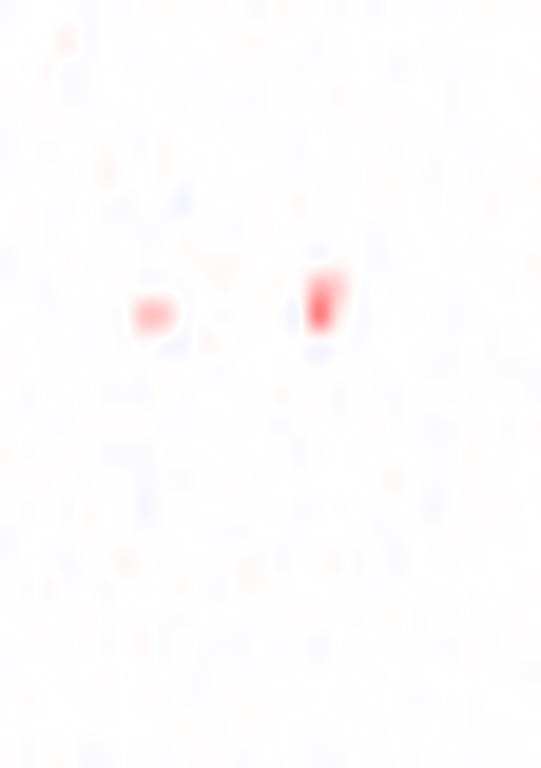
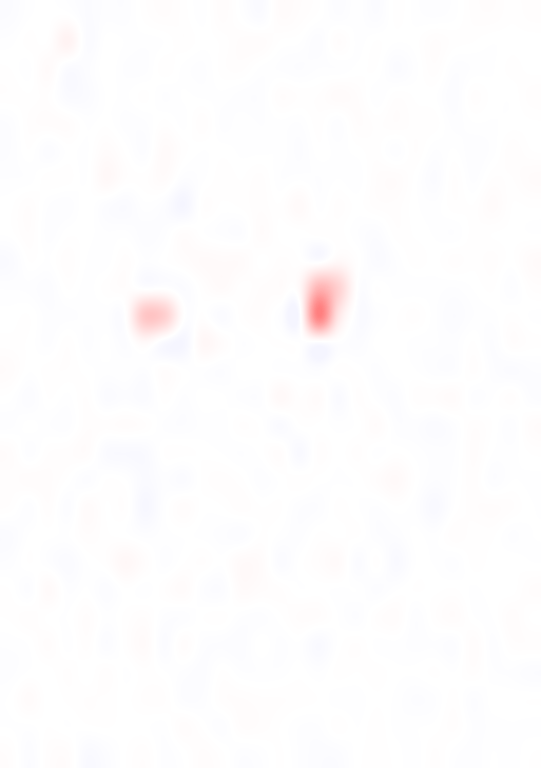
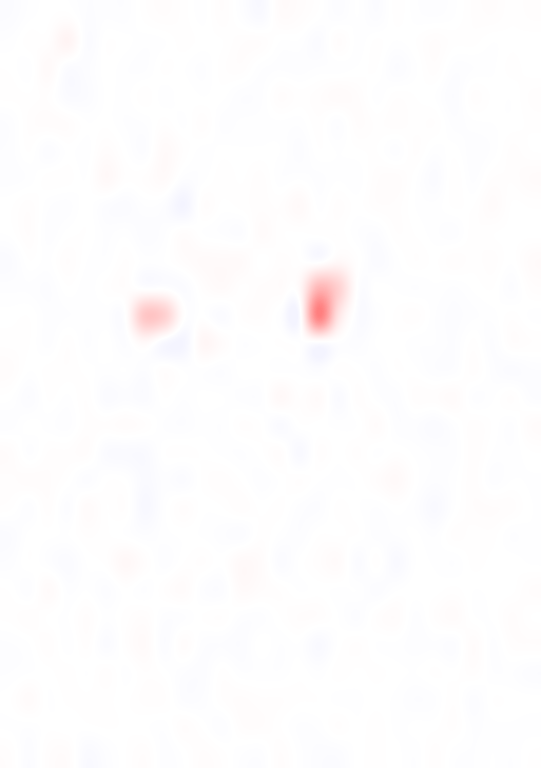
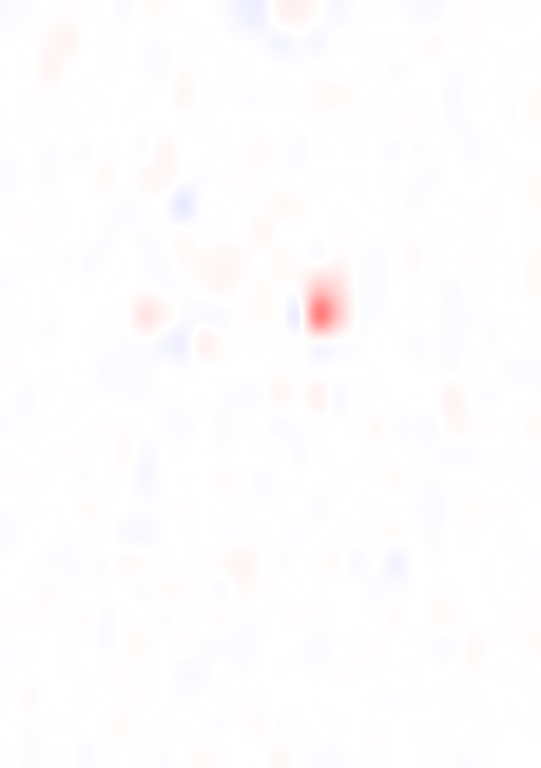
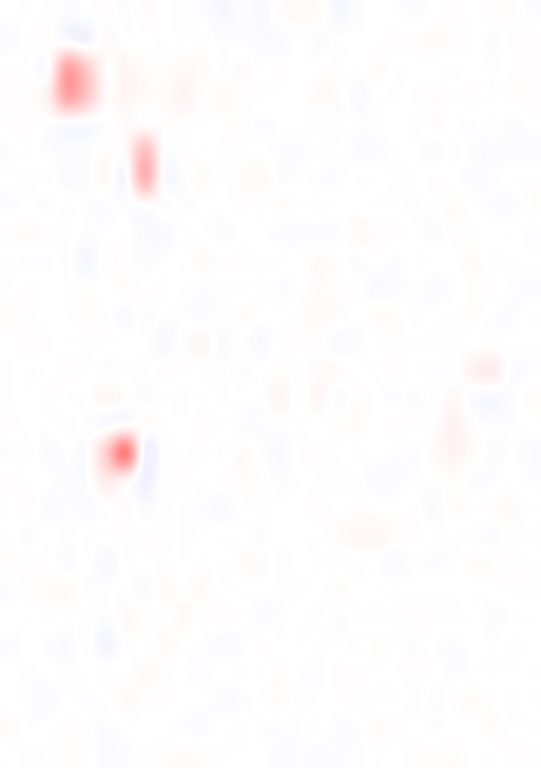
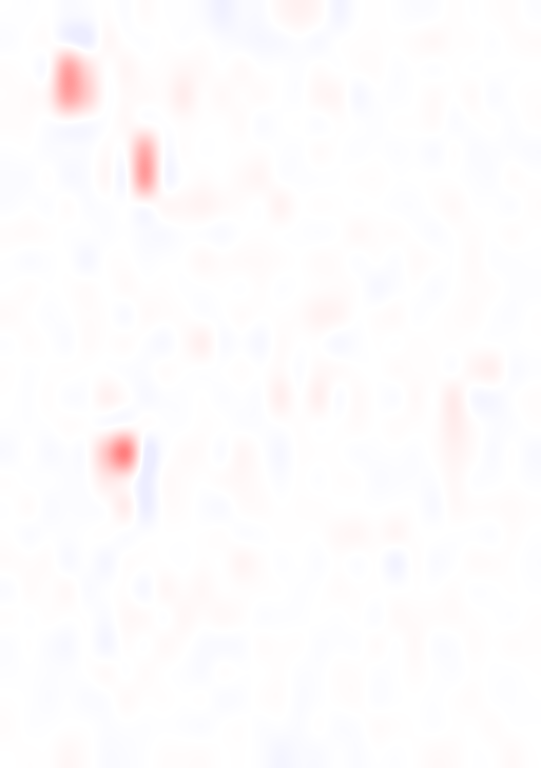
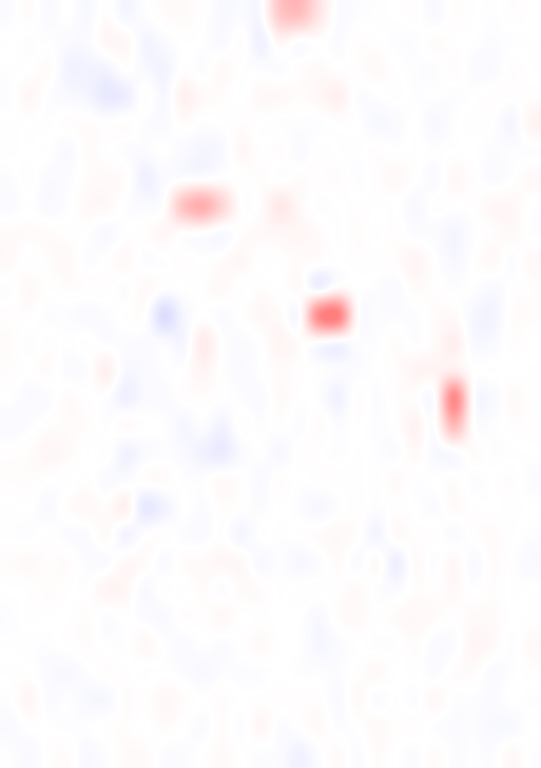
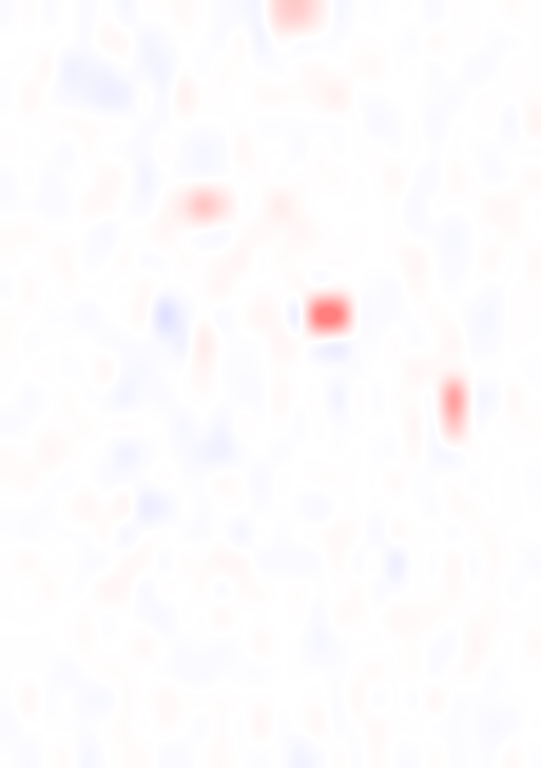
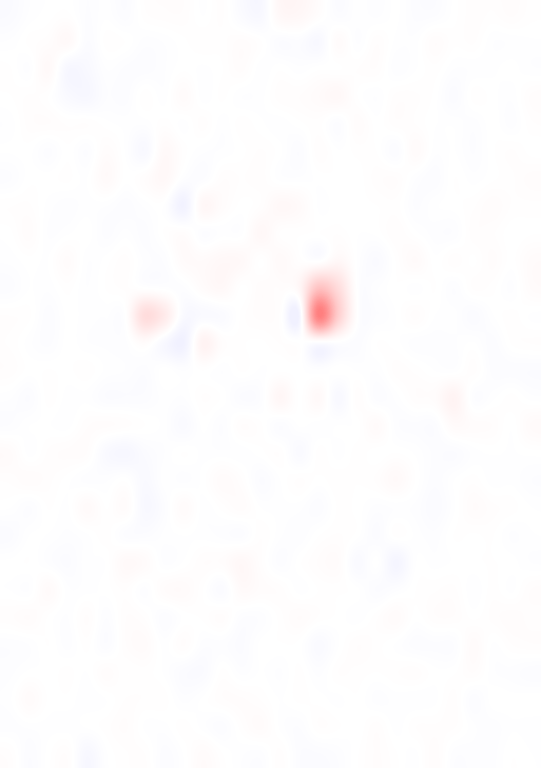

In [ ]:
# attributions = interpreto.Lime(model, processor, n_perturbations=10000)(images, queries)

plot_image_retrieval_attribution(
    attributions[0],  # ImageRetrievalAttributionOutput
    alpha=0.5,
    grayscale_background=False,
    save_path="4_ColQwen.html",
)
plot_image_retrieval_attribution(
    attributions[1],  # ImageRetrievalAttributionOutput
    alpha=0.5,
    grayscale_background=False,
    save_path="5_ColQwen.html",
)